# Beyond Economic Growth: Poverty and Development in Sub-Saharan Africa

## Project Overview

Economic growth does not necessarily translate into equivalent improvements in living standards. This project examines the relationship between economic performance and poverty reduction across Sub-Saharan African countries from 2010 to 2024.

The analysis explores whether countries experiencing improvements in economic performance have also achieved reductions in poverty, and later investigates socioeconomic factors that may help explain differences in development outcomes across countries.

### Key Questions

1. How has economic performance evolved across Sub-Saharan African countries?
2. Has economic growth been accompanied by reductions in poverty?
3. Which countries have experienced stronger or weaker improvements in development outcomes?
4. What socioeconomic factors are associated with differences in these outcomes?
5. What policy implications emerge from the observed patterns?

### Data Source

The analysis uses development indicators retrieved programmatically from the World Bank API.

## 1. Setup and Data Collection

The analysis begins by importing the Python libraries required for data retrieval, manipulation, and visualization. Data is accessed directly from the World Bank API to create a reproducible data collection process.

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("requests:", requests.__version__)
print("Core packages loaded successfully.")

pandas: 3.1.1
numpy: 2.5.4
requests: 2.34.2
Core packages loaded successfully.


### 1.1 Testing the World Bank API

Before retrieving country-level data, an initial API request is made using the Sub-Saharan Africa regional aggregate. This confirms that the World Bank API is accessible and allows inspection of the structure of the returned JSON data before scaling the request to individual countries.

In [2]:
url = "https://api.worldbank.org/v2/country/SSF/indicator/NY.GDP.PCAP.KD"

params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

response = requests.get(url, params=params)
response.raise_for_status()

print("World Bank API connection successful.")

World Bank API connection successful.


In [3]:
data = response.json()

gdp_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": item["date"],
        "real_gdp_per_capita": item["value"]
    }
    for item in data[1]
])

gdp_df.head()

,country,country_code,year,real_gdp_per_capita
0,Sub-Saharan Africa,SSF,2024,1588.939613
1,Sub-Saharan Africa,SSF,2023,1571.405580
2,Sub-Saharan Africa,SSF,2022,1568.021528
3,Sub-Saharan Africa,SSF,2021,1545.113883
4,Sub-Saharan Africa,SSF,2020,1529.910258


### 1.2 Identifying Sub-Saharan African Countries

To conduct country-level analysis, the World Bank country metadata is retrieved and filtered to countries classified within Sub-Saharan Africa. This creates a consistent list of country names and ISO3 codes that can be used across subsequent API requests.

In [4]:
countries_url = "https://api.worldbank.org/v2/country"

country_params = {
    "format": "json",
    "per_page": 400
}

countries_response = requests.get(
    countries_url,
    params=country_params
)

countries_response.raise_for_status()
countries_data = countries_response.json()

In [5]:
ssa_countries = [
    {
        "country": item["name"],
        "country_code": item["id"]
    }
    for item in countries_data[1]
    if item["region"]["value"].strip() == "Sub-Saharan Africa"
]

ssa_df = pd.DataFrame(ssa_countries)

country_codes = ";".join(
    ssa_df["country_code"]
)

print(
    f"Sub-Saharan African countries identified: {len(ssa_df)}"
)

ssa_df.head(10)

Sub-Saharan African countries identified: 48


,country,country_code
0,Angola,AGO
1,Burundi,BDI
2,Benin,BEN
3,Burkina Faso,BFA
4,Botswana,BWA
5,Central African Republic,CAF
6,Cote d'Ivoire,CIV
7,Cameroon,CMR
8,"Congo, Dem. Rep.",COD
9,"Congo, Rep.",COG


### 1.3 Real GDP per Capita

Real GDP per capita is used as the primary measure of economic performance. Unlike GDP per capita measured in current prices, the constant-price measure adjusts for changes in the domestic price level and is therefore more appropriate for examining changes in real economic activity over time.

Annual country-level data are retrieved for the 48 Sub-Saharan African countries in the sample from 2010 to 2024.

The indicator used is **GDP per capita (constant 2015 US$)** (`NY.GDP.PCAP.KD`). Missing observations are retained at this stage rather than imputed or removed, allowing data availability to be assessed before analytical decisions are made.

In [6]:
gdp_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/NY.GDP.PCAP.KD"
)

gdp_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

gdp_response = requests.get(
    gdp_url,
    params=gdp_params
)

gdp_response.raise_for_status()
gdp_data = gdp_response.json()

gdp_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "real_gdp_per_capita": item["value"]
    }
    for item in gdp_data[1]
])

gdp_df.head()

,country,country_code,year,real_gdp_per_capita
0,Angola,AGO,2024,2798.593928
1,Angola,AGO,2023,2748.951970
2,Angola,AGO,2022,2798.017173
3,Angola,AGO,2021,2788.167371
4,Angola,AGO,2020,2847.242416


In [7]:
print("Dataset shape:", gdp_df.shape)
print("Number of countries:", gdp_df["country"].nunique())
print("Year range:", gdp_df["year"].min(), "-", gdp_df["year"].max())
print(
    "Missing real GDP per capita values:",
    gdp_df["real_gdp_per_capita"].isna().sum()
)

Dataset shape: (720, 4)
Number of countries: 48
Year range: 2010 - 2024
Missing real GDP per capita values: 22


In [8]:
gdp_df[gdp_df["real_gdp_per_capita"].isna()][
    ["country", "year", "real_gdp_per_capita"]
]

,country,year,real_gdp_per_capita
180,Eritrea,2024,NaN
181,Eritrea,2023,NaN
182,Eritrea,2022,NaN
183,Eritrea,2021,NaN
184,Eritrea,2020,NaN
185,Eritrea,2019,NaN
186,Eritrea,2018,NaN
187,Eritrea,2017,NaN
188,Eritrea,2016,NaN
189,Eritrea,2015,NaN


## 2. Poverty Data

Poverty reduction is the primary development outcome examined in this project. To assess whether improvements in economic performance have translated into better living standards, poverty headcount data are retrieved for the same countries and period.

The analysis uses the World Bank's **poverty headcount ratio at $3.00 a day (2021 PPP)** (`SI.POV.DDAY`), expressed as the percentage of the population living below the international poverty line.

Unlike GDP, poverty estimates are not necessarily available annually for every country because they often depend on household survey data. Data coverage will therefore be assessed before deciding how the poverty series should be incorporated into the analysis.

In [9]:
poverty_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/SI.POV.DDAY"
)

poverty_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

poverty_response = requests.get(
    poverty_url,
    params=poverty_params
)

poverty_response.raise_for_status()
poverty_data = poverty_response.json()

poverty_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "poverty_rate": item["value"]
    }
    for item in poverty_data[1]
])

poverty_df.head()

,country,country_code,year,poverty_rate
0,Angola,AGO,2024,NaN
1,Angola,AGO,2023,NaN
2,Angola,AGO,2022,NaN
3,Angola,AGO,2021,NaN
4,Angola,AGO,2020,NaN


In [10]:
print("Dataset shape:", poverty_df.shape)
print("Number of countries:", poverty_df["country"].nunique())
print("Total observations:", len(poverty_df))
print("Available poverty observations:", poverty_df["poverty_rate"].notna().sum())
print("Missing poverty observations:", poverty_df["poverty_rate"].isna().sum())
print(
    "Data availability:",
    round(poverty_df["poverty_rate"].notna().mean() * 100, 1),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Total observations: 720
Available poverty observations: 109
Missing poverty observations: 611
Data availability: 15.1 %


In [11]:
poverty_coverage = (
    poverty_df.groupby("country")["poverty_rate"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="available_years")
)

poverty_coverage

,country,available_years
0,Nigeria,5
1,Benin,4
2,Togo,4
3,Niger,4
4,Rwanda,4
5,Uganda,4
6,Kenya,4
7,Burkina Faso,3
8,Ethiopia,3
9,Guinea-Bissau,3


### Poverty Data Coverage

Poverty data are substantially less frequent than annual macroeconomic indicators. Of the 720 possible country-year observations in the 2010–2024 sample, 109 contain reported poverty estimates, representing approximately 15.1% coverage.

However, the limitation is primarily temporal rather than geographic. Most Sub-Saharan African countries have at least one poverty observation during the period, but estimates are available only for selected survey years.

Consequently, missing poverty observations will not be treated as zero or automatically interpolated. Subsequent analysis will account for the survey-based nature of the poverty data and use observed poverty estimates only where appropriate.

## 3. Factors Associated with Poverty Outcomes

Economic performance alone may not fully explain differences in poverty outcomes across countries. The analysis therefore considers selected socioeconomic and macroeconomic conditions that may influence how improvements in economic performance translate into household welfare.

The analysis examines five dimensions:

- **Labour market outcomes** – whether economic activity is accompanied by opportunities for employment.
- **Education and human capital** – the capacity of individuals to participate in and benefit from economic opportunities.
- **Access to basic and productive infrastructure** – whether households have access to services that can support economic participation and improvements in living standards.
- **Macroeconomic stability** – particularly whether inflation may erode household purchasing power and weaken the welfare gains associated with economic growth.
- **Income distribution** – whether the gains associated with economic activity are broadly distributed across the population.

Indicators representing these dimensions are selected based on their conceptual relevance to poverty and household welfare, as well as their availability across Sub-Saharan African countries.

The analysis is primarily associational. Observed relationships between these factors and poverty outcomes should therefore not be interpreted as evidence of causality.

### 3.1 Employment

Employment provides one potential channel through which economic growth can improve household welfare. This analysis considers the employment-to-population ratio as an indicator of the extent to which the working-age population participates in employment.

Before including the indicator in the final analytical dataset, its availability across countries and years will be assessed.

In [12]:
employment_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/SL.EMP.TOTL.SP.ZS"
)

employment_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

employment_response = requests.get(
    employment_url,
    params=employment_params
)

employment_response.raise_for_status()
employment_data = employment_response.json()

employment_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "employment_rate": item["value"]
    }
    for item in employment_data[1]
])

employment_df.head()

,country,country_code,year,employment_rate
0,Angola,AGO,2024,64.383
1,Angola,AGO,2023,64.369
2,Angola,AGO,2022,64.619
3,Angola,AGO,2021,64.306
4,Angola,AGO,2020,61.078


In [13]:
print("Dataset shape:", employment_df.shape)
print("Number of countries:", employment_df["country"].nunique())
print("Available employment observations:", employment_df["employment_rate"].notna().sum())
print("Missing employment observations:", employment_df["employment_rate"].isna().sum())
print(
    "Data availability:",
    round(employment_df["employment_rate"].notna().mean() * 100, 1),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Available employment observations: 702
Missing employment observations: 18
Data availability: 97.5 %


### 3.2 Education and Human Capital

Education can influence the extent to which individuals participate in and benefit from economic opportunities. Improvements in human capital may therefore strengthen the relationship between economic growth, employment, and poverty reduction.

An appropriate education indicator should capture meaningful differences in human capital while maintaining sufficient coverage across countries and years. Candidate indicators will therefore be assessed for data availability before inclusion in the final analysis.

In [14]:
education_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/SE.SEC.CMPT.LO.ZS"
)

education_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

education_response = requests.get(
    education_url,
    params=education_params
)

education_response.raise_for_status()
education_data = education_response.json()

education_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "secondary_completion_rate": item["value"]
    }
    for item in education_data[1]
])

education_df.head()

,country,country_code,year,secondary_completion_rate
0,Angola,AGO,2024,NaN
1,Angola,AGO,2023,42.124633
2,Angola,AGO,2022,NaN
3,Angola,AGO,2021,44.939547
4,Angola,AGO,2020,NaN


In [15]:
print("Dataset shape:", education_df.shape)
print("Number of countries:", education_df["country"].nunique())
print("Available education observations:", education_df["secondary_completion_rate"].notna().sum())
print("Missing education observations:", education_df["secondary_completion_rate"].isna().sum())
print(
    "Data availability:",
    round(education_df["secondary_completion_rate"].notna().mean() * 100, 1),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Available education observations: 380
Missing education observations: 340
Data availability: 52.8 %


In [16]:
primary_education_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/SE.PRM.CMPT.ZS"
)

primary_education_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

primary_education_response = requests.get(
    primary_education_url,
    params=primary_education_params
)

primary_education_response.raise_for_status()
primary_education_data = primary_education_response.json()

primary_education_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "primary_completion_rate": item["value"]
    }
    for item in primary_education_data[1]
])

print("Dataset shape:", primary_education_df.shape)
print("Number of countries:", primary_education_df["country"].nunique())
print(
    "Available observations:",
    primary_education_df["primary_completion_rate"].notna().sum()
)
print(
    "Missing observations:",
    primary_education_df["primary_completion_rate"].isna().sum()
)
print(
    "Data availability:",
    round(
        primary_education_df["primary_completion_rate"].notna().mean() * 100,
        1
    ),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Available observations: 418
Missing observations: 302
Data availability: 58.1 %


#### Education Indicator Selection

Two education indicators were assessed for inclusion in the analysis:

- **Lower-secondary completion rate:** 52.8% data availability
- **Primary completion rate:** 58.1% data availability

Although primary completion provides slightly greater coverage, the improvement is relatively modest. Lower-secondary completion is retained as the preferred education indicator because it represents a more advanced level of educational attainment and is therefore more appropriate for examining differences in human capital across countries.

Primary completion is not included in the final analytical dataset.

### 3.3 Access to Basic Infrastructure

Access to basic infrastructure can influence household welfare and the ability of individuals to participate in economic activity. Electricity access is used as a proxy for one important dimension of basic infrastructure availability rather than as a comprehensive measure of infrastructure development.

Reliable access to electricity can support productive activity, education, communication, and access to essential services. The indicator therefore provides a household-relevant measure of whether improvements in economic conditions are accompanied by broader access to basic infrastructure.

The analysis uses access to electricity as a percentage of the population. Its limitations as a partial measure of infrastructure will be considered when interpreting the results.

In [17]:
electricity_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/EG.ELC.ACCS.ZS"
)

electricity_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

electricity_response = requests.get(
    electricity_url,
    params=electricity_params
)

electricity_response.raise_for_status()
electricity_data = electricity_response.json()

electricity_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "electricity_access": item["value"]
    }
    for item in electricity_data[1]
])

electricity_df.head()

,country,country_code,year,electricity_access
0,Angola,AGO,2024,55.5
1,Angola,AGO,2023,51.1
2,Angola,AGO,2022,48.5
3,Angola,AGO,2021,48.2
4,Angola,AGO,2020,47.0


In [18]:
print("Dataset shape:", electricity_df.shape)
print("Number of countries:", electricity_df["country"].nunique())
print(
    "Available electricity observations:",
    electricity_df["electricity_access"].notna().sum()
)
print(
    "Missing electricity observations:",
    electricity_df["electricity_access"].isna().sum()
)
print(
    "Data availability:",
    round(electricity_df["electricity_access"].notna().mean() * 100, 1),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Available electricity observations: 720
Missing electricity observations: 0
Data availability: 100.0 %


### 3.4 Macroeconomic Stability

Macroeconomic conditions can influence whether economic gains translate into improvements in household welfare. In particular, high inflation can erode purchasing power and reduce the real value of household income, potentially weakening the welfare benefits associated with economic growth.

Annual consumer price inflation is therefore considered as a measure of macroeconomic stability. The indicator is treated as a factor potentially associated with poverty outcomes rather than as a direct causal determinant.

In [19]:
inflation_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/FP.CPI.TOTL.ZG"
)

inflation_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

inflation_response = requests.get(
    inflation_url,
    params=inflation_params
)

inflation_response.raise_for_status()
inflation_data = inflation_response.json()

inflation_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "inflation_rate": item["value"]
    }
    for item in inflation_data[1]
])

inflation_df.head()

,country,country_code,year,inflation_rate
0,Angola,AGO,2024,28.240495
1,Angola,AGO,2023,13.644102
2,Angola,AGO,2022,21.355290
3,Angola,AGO,2021,25.754295
4,Angola,AGO,2020,22.271539


In [20]:
print("Dataset shape:", inflation_df.shape)
print("Number of countries:", inflation_df["country"].nunique())
print(
    "Available inflation observations:",
    inflation_df["inflation_rate"].notna().sum()
)
print(
    "Missing inflation observations:",
    inflation_df["inflation_rate"].isna().sum()
)
print(
    "Data availability:",
    round(inflation_df["inflation_rate"].notna().mean() * 100, 1),
    "%"
)

Dataset shape: (720, 4)
Number of countries: 48
Available inflation observations: 673
Missing inflation observations: 47
Data availability: 93.5 %


### 3.5 Income Distribution

Aggregate economic growth does not indicate how increases in income or consumption are distributed across the population. Where inequality is high or increasing, gains in average economic performance may coexist with limited improvements in the living standards of lower-income households.

The Gini index is therefore assessed as a potential measure of income or consumption inequality. Higher values indicate greater inequality, while lower values indicate a more equal distribution.

Because Gini estimates are generally derived from household surveys and are not available annually for every country, data coverage is assessed before the indicator is incorporated into the final analytical framework.

In [21]:
gini_url = (
    f"https://api.worldbank.org/v2/country/"
    f"{country_codes}/indicator/SI.POV.GINI"
)

gini_params = {
    "format": "json",
    "per_page": 20000,
    "date": "2010:2024"
}

gini_response = requests.get(
    gini_url,
    params=gini_params
)

gini_response.raise_for_status()
gini_data = gini_response.json()

gini_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "country_code": item["countryiso3code"],
        "year": int(item["date"]),
        "gini_index": item["value"]
    }
    for item in gini_data[1]
])

print("Dataset shape:", gini_df.shape)
print("Number of countries:", gini_df["country"].nunique())
print(
    "Available Gini observations:",
    gini_df["gini_index"].notna().sum()
)
print(
    "Missing Gini observations:",
    gini_df["gini_index"].isna().sum()
)
print(
    "Data availability:",
    round(gini_df["gini_index"].notna().mean() * 100, 1),
    "%"
)

gini_df.head()

Dataset shape: (720, 4)
Number of countries: 48
Available Gini observations: 109
Missing Gini observations: 611
Data availability: 15.1 %


,country,country_code,year,gini_index
0,Angola,AGO,2024,NaN
1,Angola,AGO,2023,NaN
2,Angola,AGO,2022,NaN
3,Angola,AGO,2021,NaN
4,Angola,AGO,2020,NaN


#### Gini Data Coverage

The Gini index is available for 109 of the 720 possible country-year observations, equivalent to 15.1% annual coverage. This sparsity is expected because inequality estimates, like poverty estimates, are generally derived from household surveys rather than reported annually.

Because the project's poverty analysis also relies on survey-year observations, overall annual coverage alone does not determine whether the Gini index is analytically useful. The relevant consideration is the extent to which inequality estimates are available in the same country-years as observed poverty estimates.

In [22]:
poverty_gini_overlap = pd.merge(
    poverty_df[
        ["country_code", "year", "poverty_rate"]
    ],
    gini_df[
        ["country_code", "year", "gini_index"]
    ],
    on=["country_code", "year"],
    how="inner"
)

observed_poverty = poverty_gini_overlap[
    poverty_gini_overlap["poverty_rate"].notna()
]

print(
    "Observed poverty country-years:",
    poverty_df["poverty_rate"].notna().sum()
)

print(
    "Observed poverty country-years with Gini:",
    observed_poverty["gini_index"].notna().sum()
)

print(
    "Gini coverage within observed poverty years:",
    round(
        observed_poverty["gini_index"].notna().mean() * 100,
        1
    ),
    "%"
)

Observed poverty country-years: 109
Observed poverty country-years with Gini: 109
Gini coverage within observed poverty years: 100.0 %


#### Indicator Selection Decision

Although the Gini index has limited annual coverage across the full 2010–2024 country-year panel, it is available for **all 109 country-years in which poverty is observed**.

This complete overlap makes inequality particularly suitable for the poverty-focused component of the analysis. The Gini index is therefore retained as a core explanatory indicator for examining how the distribution of economic resources is associated with differences in poverty outcomes.

The result also highlights an important distinction between overall data availability and analytical availability: an indicator with sparse annual coverage may still be highly useful when its observations align closely with the outcome being studied.

## 4. Data Integration and Preparation

The selected indicators are stored as separate country-year datasets. To support comparative analysis, they are combined into a single analytical dataset using country code and year as the common identifiers.

An outer-merge approach is initially used to preserve all available country-year observations across the selected indicators. Missing values are retained at this stage so that data availability can be assessed systematically before decisions are made regarding the analytical sample.

In [23]:
# Start with real GDP per capita as the base dataset
master_df = gdp_df.copy()

# Merge all remaining indicators
datasets_to_merge = [
    (poverty_df, "poverty_rate"),
    (employment_df, "employment_rate"),
    (education_df, "secondary_completion_rate"),
    (electricity_df, "electricity_access"),
    (inflation_df, "inflation_rate"),
    (gini_df, "gini_index")
]

for df, column in datasets_to_merge:
    master_df = pd.merge(
        master_df,
        df[["country_code", "year", column]],
        on=["country_code", "year"],
        how="outer"
    )

# Sort the completed country-year panel
master_df = master_df.sort_values(
    ["country", "year"]
).reset_index(drop=True)

master_df.head(10)

,country,country_code,year,real_gdp_per_capita,poverty_rate,employment_rate,secondary_completion_rate,electricity_access,inflation_rate,gini_index
0,Angola,AGO,2010,3540.791596,NaN,64.438,NaN,35.0,14.469656,NaN
1,Angola,AGO,2011,3528.168244,NaN,64.350,22.277971,34.6,13.482468,NaN
2,Angola,AGO,2012,3682.352293,NaN,64.296,NaN,37.3,10.277905,NaN
3,Angola,AGO,2013,3716.297187,NaN,64.119,NaN,38.4,8.777814,NaN
4,Angola,AGO,2014,3746.816200,NaN,63.952,NaN,32.0,7.280387,NaN
5,Angola,AGO,2015,3641.728939,NaN,63.638,NaN,42.0,9.355972,NaN
6,Angola,AGO,2016,3505.596347,NaN,63.321,NaN,41.8,30.694415,NaN
7,Angola,AGO,2017,3378.075881,NaN,63.045,NaN,42.9,29.844480,NaN
8,Angola,AGO,2018,3246.878571,39.3,62.812,NaN,45.3,19.628938,51.3
9,Angola,AGO,2019,3105.599712,NaN,62.644,NaN,45.6,17.080954,NaN


In [24]:
print("Dataset shape:", master_df.shape)
print("Number of countries:", master_df["country_code"].nunique())
print("Year range:", master_df["year"].min(), "-", master_df["year"].max())
print(
    "Duplicate country-year rows:",
    master_df.duplicated(subset=["country_code", "year"]).sum()
)

print("\nMissing values:")
print(master_df.isna().sum())

Dataset shape: (720, 10)
Number of countries: 48
Year range: 2010 - 2024
Duplicate country-year rows: 0

Missing values:
country                        0
country_code                   0
year                           0
real_gdp_per_capita           22
poverty_rate                 611
employment_rate               18
secondary_completion_rate    340
electricity_access             0
inflation_rate                47
gini_index                   611
dtype: int64


In [25]:
master_df.to_csv(
    "ssa_development_master_2010_2024.csv",
    index=False
)

print("Master dataset saved successfully.")

Master dataset saved successfully.


## 5. Exploratory Data Analysis

This section explores patterns in economic performance, poverty, employment, education, electricity access, and inflation across Sub-Saharan Africa.

The analysis proceeds from broad descriptive patterns to the project's central question: whether stronger economic performance is consistently associated with lower poverty, and which socioeconomic conditions characterize countries with different poverty outcomes.

Because poverty observations are available only for selected survey years, analyses involving poverty use observed estimates rather than treating missing country-year observations as zero or interpolating values.

### 5.1 Descriptive Statistics

Summary statistics provide an initial view of the distribution and variation of the selected development indicators across the country-year dataset.

In [26]:
indicators = [
    "real_gdp_per_capita",
    "poverty_rate",
    "employment_rate",
    "secondary_completion_rate",
    "electricity_access",
    "inflation_rate",
    "gini_index"
]
master_df[indicators].describe().round(2)

,real_gdp_per_capita,poverty_rate,employment_rate,secondary_completion_rate,electricity_access,inflation_rate,gini_index
count,698.00,109.00,702.00,380.00,720.00,673.00,109.00
mean,2259.54,42.63,58.86,48.15,46.81,10.66,40.90
std,2990.45,21.99,14.63,25.12,25.80,33.94,6.88
min,253.31,0.50,20.51,8.55,1.50,-6.69,29.60
25%,686.12,27.80,50.12,30.15,24.18,2.25,35.70
50%,1131.97,39.90,60.22,42.35,46.80,5.00,38.80
75%,2198.55,60.50,71.00,62.83,64.22,9.07,44.30
max,19481.65,85.30,85.84,147.36,100.00,557.20,60.90


### 5.2 Data Quality and Extreme Values

Before interpreting the distributions, unusually high or low observations are examined to distinguish potentially valid country-year conditions from possible data-quality issues. Extreme observations are not automatically removed, as they may represent genuine economic or social conditions.

In [27]:
print("Highest secondary completion observations:")
display(
    master_df.nlargest(
        10, "secondary_completion_rate"
    )[["country", "year", "secondary_completion_rate"]]
)

print("\nHighest inflation observations:")
display(
    master_df.nlargest(
        10, "inflation_rate"
    )[["country", "year", "inflation_rate"]]
)

Highest secondary completion observations:


,country,year,secondary_completion_rate
563,Seychelles,2018,147.362978
562,Seychelles,2017,139.655172
565,Seychelles,2020,139.024390
564,Seychelles,2019,137.500000
566,Seychelles,2021,129.478261
559,Seychelles,2014,121.551724
560,Seychelles,2015,118.432027
558,Seychelles,2013,116.286920
561,Seychelles,2016,115.604575
555,Seychelles,2010,108.203678



Highest inflation observations:


,country,year,inflation_rate
715,Zimbabwe,2020,557.201817
621,South Sudan,2016,379.999586
641,Sudan,2021,359.093041
714,Zimbabwe,2019,255.304991
622,South Sudan,2017,187.851630
640,Sudan,2020,163.257782
642,Sudan,2022,138.808460
717,Zimbabwe,2022,104.705171
716,Zimbabwe,2021,98.546105
629,South Sudan,2024,91.440822


#### Treatment of Extreme Observations

Inspection of extreme observations indicates that unusually high values should not automatically be treated as data errors.

Lower-secondary completion rates above 100% can occur because the indicator is calculated using new entrants to the final grade regardless of age relative to the population at the official entrance age. Late entry, repetition, early entry, and differences in population estimates can therefore produce values above 100%. These observations are retained and interpreted according to the indicator's definition.

Similarly, very high inflation observations are retained because they may represent genuine episodes of severe macroeconomic instability. Because such observations can strongly influence summary statistics and statistical relationships, their influence will be considered explicitly in subsequent analysis rather than removing them solely because they are extreme.

### 5.3 Real Economic Performance Across Sub-Saharan Africa

The analysis first examines differences in real economic performance across countries and over time. Real GDP per capita provides an inflation-adjusted measure of economic output per person, allowing changes in economic performance to be compared across the 2010–2024 period.

Changes in real GDP per capita are used to assess whether countries experienced improvements or declines in economic output per person over the period. These patterns provide the basis for subsequently examining whether stronger economic performance has been accompanied by lower poverty.

Real GDP per capita should not, however, be interpreted as a direct measure of household welfare. Improvements in average economic output may not be distributed evenly across the population, which motivates the project's subsequent analysis of poverty and other socioeconomic conditions.

In [28]:
real_gdp_change = (
    master_df[
        master_df["year"].isin([2010, 2024])
    ]
    .pivot(
        index="country",
        columns="year",
        values="real_gdp_per_capita"
    )
    .reset_index()
)

real_gdp_change["percent_change"] = (
    (real_gdp_change[2024] - real_gdp_change[2010])
    / real_gdp_change[2010]
) * 100

real_gdp_change = real_gdp_change.sort_values(
    "percent_change",
    ascending=False
)

real_gdp_change.round(2)

year,country,2010,2024,percent_change
16,Ethiopia,421.90,883.46,109.40
34,Rwanda,579.42,1043.16,80.04
19,Ghana,1381.23,2173.00,57.32
12,Cote d'Ivoire,1540.53,2395.66,55.51
20,Guinea,675.74,1045.92,54.78
44,Togo,686.01,1053.82,53.61
29,Mauritius,8100.95,11918.80,47.13
1,Benin,928.25,1324.78,42.72
39,"Somalia, Fed. Rep.",329.97,467.27,41.61
43,Tanzania,801.30,1120.77,39.87


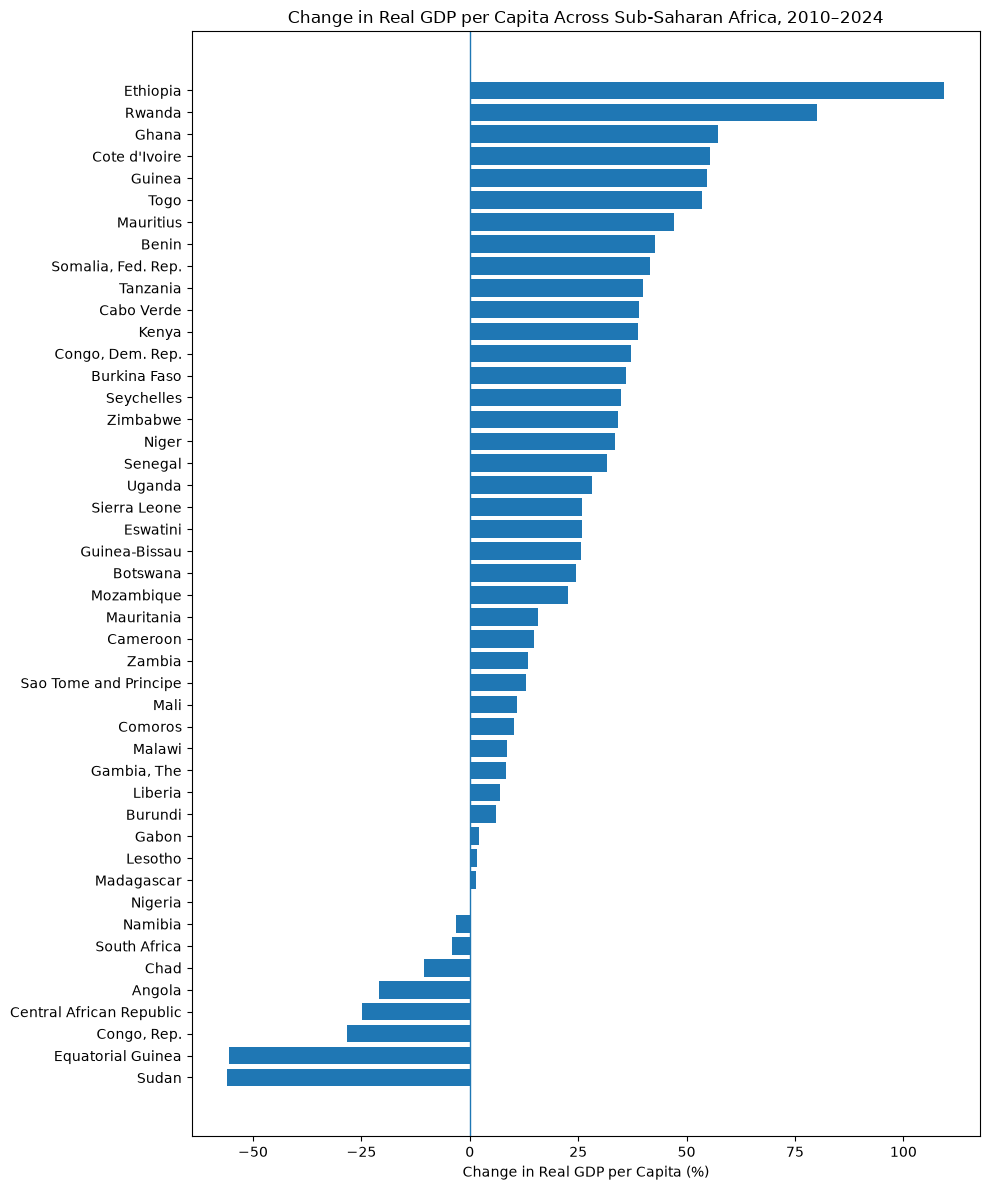

In [71]:
plot_data = real_gdp_change.dropna(
    subset=["percent_change"]
).sort_values("percent_change")

plt.figure(figsize=(10, 12))

plt.barh(
    plot_data["country"],
    plot_data["percent_change"]
)

plt.axvline(0, linewidth=1)

plt.title(
    "Change in Real GDP per Capita Across Sub-Saharan Africa, 2010–2024"
)
plt.xlabel("Change in Real GDP per Capita (%)")
plt.ylabel("")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "real_gdp_per_capita_change.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#### Key Finding: Real Economic Performance Diverged Substantially

Real GDP per capita trajectories varied considerably across Sub-Saharan Africa between 2010 and 2024. Ethiopia and Rwanda recorded some of the largest increases in the sample, with real GDP per capita rising by approximately 109% and 80%, respectively. Several other countries, including Ghana, Côte d'Ivoire, Guinea, and Togo, also experienced increases exceeding 50%.

However, improvements were not universal. Real GDP per capita remained broadly unchanged in some countries, including Nigeria, while countries such as Angola, the Central African Republic, the Republic of Congo, Equatorial Guinea, and Sudan experienced substantial declines between the two endpoints.

These differences demonstrate that regional averages can obscure considerable variation in country-level economic performance. The next stage examines whether countries experiencing stronger real economic gains also recorded improvements in poverty outcomes.

### 5.4 Economic Performance and Poverty Reduction

The central analysis examines whether improvements in real economic performance have been accompanied by reductions in poverty.

Because poverty estimates are not available annually for most countries, a fixed 2010–2024 comparison would exclude much of the sample. Instead, for each country with at least two poverty observations, the analysis identifies the first and latest available poverty estimates within the study period.

Changes in poverty are then compared with changes in real GDP per capita over the corresponding country-specific interval. This approach preserves observed poverty data and avoids interpolating unreported survey years.

In [30]:
poverty_observed = master_df.dropna(
    subset=["poverty_rate"]
).copy()

poverty_periods = (
    poverty_observed
    .sort_values(["country", "year"])
    .groupby("country")
    .agg(
        first_poverty_year=("year", "first"),
        latest_poverty_year=("year", "last"),
        first_poverty_rate=("poverty_rate", "first"),
        latest_poverty_rate=("poverty_rate", "last"),
        poverty_observations=("poverty_rate", "count")
    )
    .reset_index()
)

poverty_periods = poverty_periods[
    poverty_periods["poverty_observations"] >= 2
]

poverty_periods.head(10)

,country,first_poverty_year,latest_poverty_year,first_poverty_rate,latest_poverty_rate,poverty_observations
1,Benin,2011,2021,68.4,27.2,4
3,Burkina Faso,2014,2021,58.7,42.1,3
4,Burundi,2013,2020,75.8,74.2,2
6,Cameroon,2014,2021,29.0,26.7,2
8,Chad,2011,2022,45.2,39.5,3
9,Comoros,2014,2024,31.4,5.1,3
10,"Congo, Dem. Rep.",2012,2020,78.9,85.3,2
12,Cote d'Ivoire,2015,2021,46.6,20.8,3
15,Ethiopia,2010,2021,37.4,38.6,3
17,"Gambia, The",2010,2020,34.2,22.0,3


In [31]:
print(
    "Countries with at least two poverty observations:",
    len(poverty_periods)
)

print(
    "Countries excluded because they have fewer than two observations:",
    48 - len(poverty_periods)
)

Countries with at least two poverty observations: 34
Countries excluded because they have fewer than two observations: 14


In [32]:
analysis_periods = poverty_periods.copy()

gdp_lookup = master_df[
    ["country", "year", "real_gdp_per_capita"]
].copy()

analysis_periods = analysis_periods.merge(
    gdp_lookup,
    left_on=["country", "first_poverty_year"],
    right_on=["country", "year"],
    how="left"
).rename(
    columns={"real_gdp_per_capita": "first_real_gdp_per_capita"}
).drop(columns="year")

analysis_periods = analysis_periods.merge(
    gdp_lookup,
    left_on=["country", "latest_poverty_year"],
    right_on=["country", "year"],
    how="left"
).rename(
    columns={"real_gdp_per_capita": "latest_real_gdp_per_capita"}
).drop(columns="year")

analysis_periods["poverty_change_pp"] = (
    analysis_periods["latest_poverty_rate"]
    - analysis_periods["first_poverty_rate"]
)

analysis_periods["real_gdp_change_pct"] = (
    (
        analysis_periods["latest_real_gdp_per_capita"]
        - analysis_periods["first_real_gdp_per_capita"]
    )
    / analysis_periods["first_real_gdp_per_capita"]
) * 100

analysis_periods[
    [
        "country",
        "first_poverty_year",
        "latest_poverty_year",
        "poverty_change_pp",
        "real_gdp_change_pct"
    ]
].round(2)

,country,first_poverty_year,latest_poverty_year,poverty_change_pp,real_gdp_change_pct
0,Benin,2011,2021,-41.2,26.80
1,Burkina Faso,2014,2021,-16.6,19.36
2,Burundi,2013,2020,-1.6,1.60
3,Cameroon,2014,2021,-2.3,4.47
4,Chad,2011,2022,-5.7,-10.64
5,Comoros,2014,2024,-26.3,4.48
6,"Congo, Dem. Rep.",2012,2020,6.4,15.13
7,Cote d'Ivoire,2015,2021,-25.8,18.28
8,Ethiopia,2010,2021,1.2,87.40
9,"Gambia, The",2010,2020,-12.2,-4.32


#### Relationship Between Real Economic Growth and Poverty Change

To examine whether stronger economic performance has been accompanied by poverty reduction, the percentage change in real GDP per capita is compared with the change in the poverty headcount rate over each country's available survey interval.

Because the starting and ending poverty survey years differ across countries, the corresponding real GDP per capita change is calculated over the same country-specific period.

The scatter plot is divided into four analytical quadrants:

- **Growth with poverty reduction:** real GDP per capita increased while poverty declined.
- **Growth without poverty reduction:** real GDP per capita increased while poverty increased.
- **Poverty reduction despite economic contraction:** real GDP per capita declined while poverty declined.
- **Economic contraction with rising poverty:** real GDP per capita declined while poverty increased.

A reduction in poverty is represented by a negative change in percentage points. The analysis is descriptive and associational; the observed relationship should not be interpreted as evidence that changes in real GDP per capita caused changes in poverty.

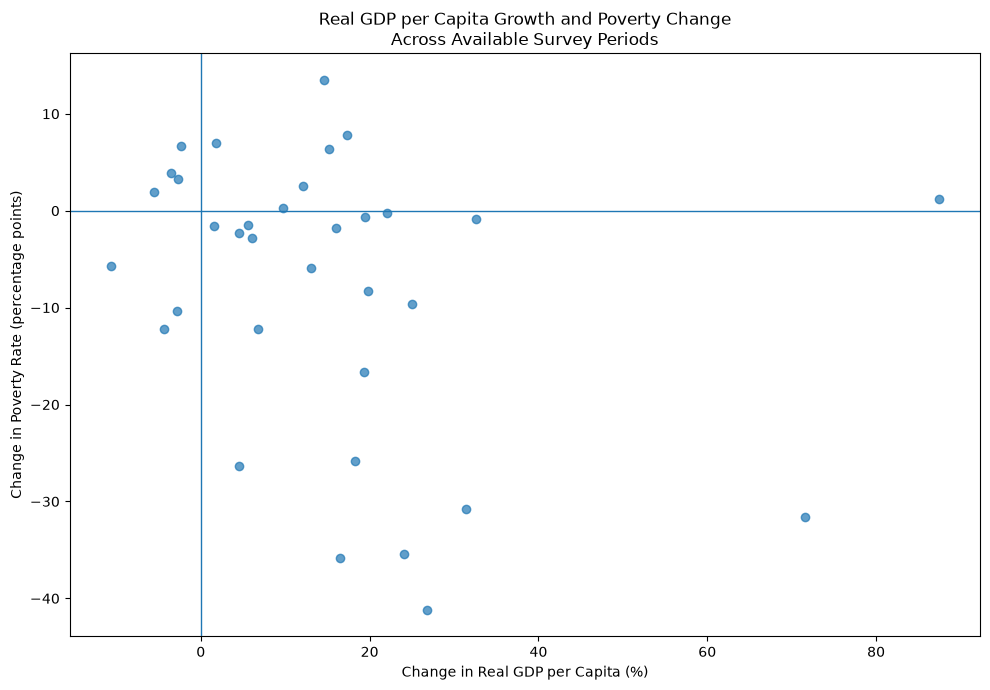

In [70]:
plt.figure(figsize=(10, 7))

plt.scatter(
    analysis_periods["real_gdp_change_pct"],
    analysis_periods["poverty_change_pp"],
    alpha=0.7
)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.xlabel("Change in Real GDP per Capita (%)")
plt.ylabel("Change in Poverty Rate (percentage points)")
plt.title(
    "Real GDP per Capita Growth and Poverty Change\n"
    "Across Available Survey Periods"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "growth_poverty_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Growth–Poverty Patterns

The scatter plot indicates substantial variation in how poverty outcomes have evolved alongside changes in real GDP per capita. To make these differences more explicit, countries are classified according to whether real GDP per capita increased or declined and whether the observed poverty rate increased or declined over the corresponding period.

This classification is descriptive and is intended to identify contrasting development trajectories rather than establish causal relationships.

In [34]:
def classify_growth_poverty(row):
    if row["real_gdp_change_pct"] >= 0 and row["poverty_change_pp"] < 0:
        return "Growth + Poverty Reduction"
    elif row["real_gdp_change_pct"] >= 0 and row["poverty_change_pp"] >= 0:
        return "Growth + Poverty Increase"
    elif row["real_gdp_change_pct"] < 0 and row["poverty_change_pp"] < 0:
        return "Contraction + Poverty Reduction"
    else:
        return "Contraction + Poverty Increase"


analysis_periods["growth_poverty_pattern"] = analysis_periods.apply(
    classify_growth_poverty,
    axis=1
)

pattern_summary = (
    analysis_periods["growth_poverty_pattern"]
    .value_counts()
    .reset_index()
)

pattern_summary.columns = ["pattern", "number_of_countries"]

pattern_summary

,pattern,number_of_countries
0,Growth + Poverty Reduction,20
1,Growth + Poverty Increase,7
2,Contraction + Poverty Increase,4
3,Contraction + Poverty Reduction,3


#### Identifying Contrasting Development Trajectories

Among countries with sufficient poverty observations, economic growth was more commonly accompanied by poverty reduction than by rising poverty. However, the presence of countries where real GDP per capita increased while poverty also increased suggests that economic growth alone does not guarantee improvements in poverty outcomes.

Identifying the countries within each trajectory allows the analysis to move beyond regional averages and examine the socioeconomic conditions associated with different growth–poverty outcomes.

In [35]:
pattern_countries = (
    analysis_periods[
        [
            "country",
            "real_gdp_change_pct",
            "poverty_change_pp",
            "growth_poverty_pattern"
        ]
    ]
    .sort_values(
        ["growth_poverty_pattern", "real_gdp_change_pct"],
        ascending=[True, False]
    )
)

pattern_countries.round(2)

,country,real_gdp_change_pct,poverty_change_pp,growth_poverty_pattern
17,Mali,-2.31,6.7,Contraction + Poverty Increase
22,Nigeria,-2.64,3.3,Contraction + Poverty Increase
15,Madagascar,-3.54,3.9,Contraction + Poverty Increase
14,Liberia,-5.53,1.9,Contraction + Poverty Increase
28,South Africa,-2.81,-10.4,Contraction + Poverty Reduction
9,"Gambia, The",-4.32,-12.2,Contraction + Poverty Reduction
4,Chad,-10.64,-5.7,Contraction + Poverty Reduction
8,Ethiopia,87.40,1.2,Growth + Poverty Increase
13,Kenya,17.35,7.8,Growth + Poverty Increase
6,"Congo, Dem. Rep.",15.13,6.4,Growth + Poverty Increase


### 5.5 Socioeconomic and Distributional Conditions Associated with Growth–Poverty Outcomes

The preceding analysis shows that increases in real GDP per capita were not uniformly accompanied by reductions in poverty. This section examines whether labour-market conditions, human capital, access to electricity, macroeconomic stability, and income distribution differ between countries where economic growth coincided with poverty reduction and those where growth coincided with rising poverty.

Where appropriate, changes in these indicators are measured over the same country-specific intervals defined by the first and latest available poverty observations. This alignment ensures that socioeconomic changes are evaluated over periods corresponding directly to the observed poverty changes.

The analysis remains exploratory and associational. Differences between groups may reveal potentially important development patterns, but they should not be interpreted as causal explanations for poverty outcomes.

In [36]:
def add_endpoint_values(data, indicator, prefix):
    lookup = master_df[
        ["country", "year", indicator]
    ].copy()

    data = data.merge(
        lookup,
        left_on=["country", "first_poverty_year"],
        right_on=["country", "year"],
        how="left"
    ).rename(
        columns={indicator: f"first_{prefix}"}
    ).drop(columns="year")

    data = data.merge(
        lookup,
        left_on=["country", "latest_poverty_year"],
        right_on=["country", "year"],
        how="left"
    ).rename(
        columns={indicator: f"latest_{prefix}"}
    ).drop(columns="year")

    return data

In [37]:
factor_analysis = analysis_periods.copy()

factor_analysis = add_endpoint_values(
    factor_analysis,
    "employment_rate",
    "employment_rate"
)

factor_analysis = add_endpoint_values(
    factor_analysis,
    "secondary_completion_rate",
    "secondary_completion_rate"
)

factor_analysis = add_endpoint_values(
    factor_analysis,
    "electricity_access",
    "electricity_access"
)

factor_analysis = add_endpoint_values(
    factor_analysis,
    "inflation_rate",
    "inflation_rate"
)

factor_analysis = add_endpoint_values(
    factor_analysis,
    "gini_index",
    "gini_index"
)

#### Availability of Socioeconomic Indicators

Because the poverty comparison periods differ across countries, each socioeconomic indicator must be available at both the first and latest poverty-observation years to calculate a comparable change over the same interval.

Coverage is therefore assessed again within the 34-country poverty-change sample before group comparisons are made.

In [38]:
endpoint_coverage = pd.DataFrame({
    "indicator": [
        "Employment",
        "Secondary completion",
        "Electricity access",
        "Inflation",
        "Gini index"
    ],
    "countries_with_both_endpoints": [
        factor_analysis[
            ["first_employment_rate", "latest_employment_rate"]
        ].notna().all(axis=1).sum(),

        factor_analysis[
            [
                "first_secondary_completion_rate",
                "latest_secondary_completion_rate"
            ]
        ].notna().all(axis=1).sum(),

        factor_analysis[
            ["first_electricity_access", "latest_electricity_access"]
        ].notna().all(axis=1).sum(),

        factor_analysis[
            ["first_inflation_rate", "latest_inflation_rate"]
        ].notna().all(axis=1).sum(),

        factor_analysis[
            ["first_gini_index", "latest_gini_index"]
        ].notna().all(axis=1).sum()
    ]
})

endpoint_coverage["coverage_pct"] = (
    endpoint_coverage["countries_with_both_endpoints"]
    / len(factor_analysis)
    * 100
)

endpoint_coverage.round(1)

,indicator,countries_with_both_endpoints,coverage_pct
0,Employment,33,97.1
1,Secondary completion,19,55.9
2,Electricity access,34,100.0
3,Inflation,33,97.1
4,Gini index,34,100.0


#### Changes in Socioeconomic Conditions

Changes in employment, electricity access, and inflation are calculated over each country's corresponding poverty-observation interval. Lower-secondary completion is also examined, but its results are interpreted separately because comparable endpoint observations are available for a smaller subset of countries.

Missing education observations are not interpolated solely to increase the analytical sample.

In [39]:
factor_analysis["employment_change_pp"] = (
    factor_analysis["latest_employment_rate"]
    - factor_analysis["first_employment_rate"]
)

factor_analysis["secondary_completion_change_pp"] = (
    factor_analysis["latest_secondary_completion_rate"]
    - factor_analysis["first_secondary_completion_rate"]
)

factor_analysis["electricity_change_pp"] = (
    factor_analysis["latest_electricity_access"]
    - factor_analysis["first_electricity_access"]
)

factor_analysis["inflation_change_pp"] = (
    factor_analysis["latest_inflation_rate"]
    - factor_analysis["first_inflation_rate"]
)

factor_analysis["gini_change"] = (
    factor_analysis["latest_gini_index"]
    - factor_analysis["first_gini_index"]
)

factor_analysis[
    [
        "country",
        "growth_poverty_pattern",
        "employment_change_pp",
        "secondary_completion_change_pp",
        "electricity_change_pp",
        "inflation_change_pp",
        "gini_change"
    ]
].round(2)

,country,growth_poverty_pattern,employment_change_pp,secondary_completion_change_pp,electricity_change_pp,inflation_change_pp,gini_change
0,Benin,Growth + Poverty Reduction,4.70,-0.62,5.1,-0.97,-9.0
1,Burkina Faso,Growth + Poverty Reduction,-4.86,13.42,-0.2,3.91,2.1
2,Burundi,Growth + Poverty Reduction,0.15,4.51,2.2,-0.62,-1.1
3,Cameroon,Growth + Poverty Reduction,-6.83,-1.44,8.6,0.42,-4.4
4,Chad,Contraction + Poverty Reduction,-3.91,NaN,2.7,3.76,-5.9
5,Comoros,Growth + Poverty Reduction,10.58,-4.00,19.9,-2.50,-15.0
6,"Congo, Dem. Rep.",Growth + Poverty Increase,-3.02,17.79,4.7,NaN,2.6
7,Cote d'Ivoire,Growth + Poverty Reduction,-0.72,NaN,8.5,2.91,-6.2
8,Ethiopia,Growth + Poverty Increase,-14.10,NaN,28.7,18.69,-2.1
9,"Gambia, The",Contraction + Poverty Reduction,1.44,6.57,15.4,0.88,-4.8


#### Comparing Countries with Different Growth–Poverty Outcomes

The analysis now focuses on countries where real GDP per capita increased, separating them into two groups: those where poverty declined and those where poverty increased.

Group medians are used as the primary descriptive comparison because several indicators, particularly inflation, contain extreme observations that could substantially distort arithmetic means. Sample sizes are reported for each indicator because missing education and other endpoint observations mean that not every comparison contains the same countries.

In [40]:
growth_groups = factor_analysis[
    factor_analysis["growth_poverty_pattern"].isin([
        "Growth + Poverty Reduction",
        "Growth + Poverty Increase"
    ])
].copy()

comparison_variables = [
    "employment_change_pp",
    "secondary_completion_change_pp",
    "electricity_change_pp",
    "inflation_change_pp",
    "gini_change"
]

group_medians = (
    growth_groups
    .groupby("growth_poverty_pattern")[comparison_variables]
    .median()
    .T
)

group_counts = (
    growth_groups
    .groupby("growth_poverty_pattern")[comparison_variables]
    .count()
    .T
)

group_comparison = group_medians.round(2).copy()

group_comparison["n_poverty_reduction"] = (
    group_counts["Growth + Poverty Reduction"]
)

group_comparison["n_poverty_increase"] = (
    group_counts["Growth + Poverty Increase"]
)

group_comparison

growth_poverty_pattern,Growth + Poverty Increase,Growth + Poverty Reduction,n_poverty_reduction,n_poverty_increase
employment_change_pp,-3.56,-0.44,19,7
secondary_completion_change_pp,13.84,6.21,14,2
electricity_change_pp,9.80,11.70,20,7
inflation_change_pp,5.11,-0.45,20,6
gini_change,-2.10,-3.45,20,7


#### Interpretation: The Translation of Growth into Poverty Reduction Depends on the Broader Development Environment

The comparison of countries experiencing increases in real GDP per capita reinforces a central finding of the analysis: **economic growth was more frequently associated with poverty reduction, but growth alone was not sufficient to ensure that poverty declined**. Among the 27 countries in which real GDP per capita increased over their respective poverty-observation intervals, 20 recorded reductions in poverty while seven recorded increases.

The differences between these groups provide insight into the conditions under which economic expansion may be more or less likely to coincide with improvements in household welfare.

##### Labour-market conditions

The employment-to-population ratio declined in both groups, suggesting that increases in real GDP per capita were not generally accompanied by increases in the proportion of the working-age population employed. The magnitude of the deterioration, however, differed considerably.

Countries where growth coincided with poverty reduction experienced a median decline of approximately **0.44 percentage points**, compared with **3.56 percentage points** among countries where poverty increased.

This pattern suggests that the **employment intensity of economic growth may be relevant to its poverty-reducing potential**. An economy can expand without generating employment opportunities proportionate to its increase in output, particularly when growth is concentrated in capital-intensive sectors, extractive activities, or relatively narrow segments of the economy. Where employment participation deteriorates substantially during periods of economic expansion, the transmission of aggregate growth to household labour income may be weaker.

The evidence does not imply that maintaining employment participation is sufficient for poverty reduction. The employment-to-population ratio does not capture wages, hours worked, informality, underemployment, labour productivity, or employment quality. Nevertheless, the substantially larger deterioration among countries where poverty increased suggests that the labour-market channel warrants attention when assessing whether growth is inclusive.

##### Income distribution

Income distribution provides an additional distinction between the two groups. Median Gini inequality declined in both, but the reduction was larger among countries where growth coincided with poverty reduction: approximately **3.45 Gini points**, compared with **2.10 points** among countries where poverty increased.

The fact that inequality declined in both groups is important because it demonstrates that changes in the Gini index alone do not mechanically determine poverty outcomes. Poverty depends on both the **level and distribution of household resources**. A modest improvement in distribution may therefore be insufficient to reduce poverty if income or consumption among households near the poverty line does not increase sufficiently, if economic shocks affect vulnerable households disproportionately, or if the starting poverty rate is particularly high.

At the same time, the larger median decline in inequality among poverty-reducing countries is consistent with the broader proposition that the **distribution of economic gains matters for the poverty elasticity of growth**. Economic expansion that is accompanied by a broader distribution of income or consumption gains may generate larger reductions in poverty than growth whose benefits remain comparatively concentrated.

Because the Gini index summarizes the entire distribution into a single statistic, it cannot identify where within the distribution changes occurred. A reduction in inequality may arise through different combinations of gains and losses across income groups. The result should therefore be interpreted as evidence of a distributional association rather than a complete account of how growth was shared.

##### Access to electricity

Electricity access improved substantially in both groups. The median increase was approximately **11.7 percentage points** among countries where poverty declined and **9.8 percentage points** among countries where poverty increased.

The relatively modest difference between the groups suggests that expansion of electricity access was a broad development trend rather than a condition uniquely associated with poverty reduction. This does not imply that electricity access is unimportant. Electrification can expand opportunities for productive activity, education, communication, and access to services. However, connection rates alone do not capture reliability, affordability, electricity consumption, productive use, or whether newly connected households are concentrated among poorer populations.

Electricity access should therefore be interpreted as an indicator of the broader development environment rather than a stand-alone explanation for differences in poverty trajectories.

##### Macroeconomic stability and purchasing power

Inflation provides one of the clearest contrasts between the two groups. Median inflation declined slightly—by approximately **0.45 percentage points**—among countries where growth coincided with poverty reduction. In contrast, median inflation increased by approximately **5.11 percentage points** among countries where poverty increased.

This difference highlights the distinction between growth in aggregate real output and the economic conditions experienced by households. Even where real GDP per capita increases, rising consumer prices can place substantial pressure on household budgets. Poor and near-poor households may be particularly exposed because essential items such as food, transport, housing, and energy account for relatively large shares of their expenditure.

The observed pattern is therefore consistent with the possibility that **macroeconomic instability can weaken the transmission of economic growth into improvements in household welfare**. Growth may increase the resources available within an economy while simultaneously failing to improve—or even worsening—the purchasing-power position of vulnerable households.

This interpretation remains subject to important limitations. Headline inflation does not capture differences in consumption baskets across income groups, wage adjustments, food-specific inflation, regional price differences, or the effects of subsidies and social protection. Moreover, the presence of extreme inflation episodes means that changes in inflation are highly heterogeneous across countries, which is why median rather than mean changes are emphasized.

##### Education and human capital

The available education data do not support a credible comparison between the two growth groups. Although the calculated median increase in lower-secondary completion is larger among countries where poverty increased, comparable education observations exist for only **two of the seven countries** in that group.

Any apparent difference would therefore be driven by an extremely small subsample and could not reasonably be generalized to the broader group. The appropriate analytical conclusion is not that education was associated with higher poverty, but that **the available endpoint data are insufficient to evaluate the human-capital channel reliably within this comparison**.

This limitation is itself relevant for development analytics: theoretically important variables should not be assigned empirical significance when the underlying data cannot support the comparison.

##### Overall assessment

Taken together, the evidence points toward a more nuanced interpretation of the growth–poverty relationship. Real GDP per capita growth was more commonly accompanied by poverty reduction than by rising poverty, but countries experiencing similar directions of economic growth displayed substantially different household-welfare outcomes.

The clearest descriptive differences between the two growth groups appear in **labour-market resilience, inflation dynamics, and—more moderately—the distribution of income or consumption**. Countries where poverty declined experienced substantially smaller deterioration in employment participation, more favourable inflation dynamics, and somewhat larger reductions in inequality. Electricity access improved considerably in both groups and therefore appears less capable of distinguishing their poverty trajectories.

These findings are consistent with an **inclusive-growth framework** in which the poverty-reducing effect of economic expansion depends not only on the quantity of growth but also on the mechanisms through which economic gains reach households and the macroeconomic environment in which those gains occur.

The evidence remains associational. Country-specific poverty intervals differ, the sample is relatively small, and the analysis does not yet account simultaneously for country characteristics or common time effects. Conflict, fiscal policy, social protection, sectoral composition, demographic change, commodity-price exposure, urbanisation, institutional conditions, and other omitted factors may also influence the observed relationships.

Consequently, the descriptive results should be treated as **hypotheses supported by observed cross-country patterns rather than causal conclusions**. The next stage of the analysis uses statistical and econometric methods to assess whether these relationships persist when examined more systematically.

## 6. Statistical Analysis

The descriptive analysis identified substantial variation in the relationship between real economic performance and poverty outcomes across countries. This section examines these relationships more systematically using statistical methods.

The analysis focuses on country-years in which poverty is directly observed rather than interpolated. This produces an unbalanced poverty-observation panel in which countries contribute observations according to the availability of household-survey data.

Two forms of correlation are considered:

- **Pearson correlation** measures the strength of linear relationships between variables.
- **Spearman rank correlation** assesses whether variables move monotonically together and is less sensitive to extreme observations and non-linear distributions.

Correlation coefficients describe statistical association and should not be interpreted as evidence of causality.

In [41]:
poverty_panel = master_df[
    master_df["poverty_rate"].notna()
].copy()

poverty_panel = poverty_panel[
    [
        "country",
        "country_code",
        "year",
        "poverty_rate",
        "real_gdp_per_capita",
        "employment_rate",
        "secondary_completion_rate",
        "electricity_access",
        "inflation_rate",
        "gini_index"
    ]
]

print("Poverty-observation panel shape:", poverty_panel.shape)
print(
    "Number of countries:",
    poverty_panel["country"].nunique()
)
print(
    "Number of poverty observations:",
    poverty_panel["poverty_rate"].notna().sum()
)

poverty_panel.head(10)

Poverty-observation panel shape: (109, 10)
Number of countries: 46
Number of poverty observations: 109


,country,country_code,year,poverty_rate,real_gdp_per_capita,employment_rate,secondary_completion_rate,electricity_access,inflation_rate,gini_index
8,Angola,AGO,2018,39.3,3246.878571,62.812,NaN,45.3,19.628938,51.3
16,Benin,BEN,2011,68.4,927.716413,69.977,34.696678,36.9,2.704239,43.4
20,Benin,BEN,2015,65.8,1002.418869,72.132,42.295078,29.6,0.218786,47.6
23,Benin,BEN,2018,37.2,1071.504522,73.642,NaN,39.0,0.919171,37.9
26,Benin,BEN,2021,27.2,1176.377276,74.681,34.075668,42.0,1.733540,34.4
35,Botswana,BWA,2015,21.4,6141.203947,50.428,NaN,62.1,3.062032,54.9
49,Burkina Faso,BFA,2014,58.7,624.576885,75.506,24.117387,19.2,-0.258090,35.3
53,Burkina Faso,BFA,2018,47.7,694.492813,74.215,41.999948,14.4,1.955943,43.0
56,Burkina Faso,BFA,2021,42.1,745.472563,70.646,37.533666,19.0,3.653268,37.4
63,Burundi,BDI,2013,75.8,259.311117,77.590,23.498704,6.9,7.937958,38.6


### 6.1 Variable Transformation

Real GDP per capita varies substantially across the countries in the sample and has a strongly right-skewed distribution. The natural logarithm of real GDP per capita is therefore used in the statistical and econometric analysis.

The logarithmic transformation reduces the influence of very high-income observations and allows subsequent regression coefficients to be interpreted in relation to proportional changes in real GDP per capita rather than absolute dollar differences.

Other indicators remain in their original units to preserve straightforward interpretation.

In [42]:
import numpy as np

poverty_panel["log_real_gdp_per_capita"] = np.log(
    poverty_panel["real_gdp_per_capita"]
)

poverty_panel[
    [
        "real_gdp_per_capita",
        "log_real_gdp_per_capita"
    ]
].describe().round(2)

,real_gdp_per_capita,log_real_gdp_per_capita
count,108.00,108.00
mean,1868.34,7.08
std,2666.33,0.83
min,259.31,5.56
25%,682.53,6.53
50%,998.16,6.91
75%,1617.14,7.39
max,18628.19,9.83


### 6.2 Bivariate Correlations with Poverty

Pearson and Spearman correlations are calculated between the poverty headcount rate and each selected economic or socioeconomic indicator.

Pearson correlation captures linear association, while Spearman correlation evaluates rank-based association and is less sensitive to extreme observations. The number of complete country-year observations used for each relationship is reported because data availability differs across indicators.

These correlations are descriptive and do not account for country-specific characteristics, common time effects, or relationships among the explanatory variables.

In [43]:
from scipy.stats import pearsonr, spearmanr

correlation_variables = {
    "Real GDP per capita (log)": "log_real_gdp_per_capita",
    "Employment rate": "employment_rate",
    "Secondary completion": "secondary_completion_rate",
    "Electricity access": "electricity_access",
    "Inflation": "inflation_rate",
    "Gini index": "gini_index"
}

correlation_results = []

for label, variable in correlation_variables.items():

    temp = poverty_panel[
        ["poverty_rate", variable]
    ].dropna()

    pearson_r, pearson_p = pearsonr(
        temp["poverty_rate"],
        temp[variable]
    )

    spearman_r, spearman_p = spearmanr(
        temp["poverty_rate"],
        temp[variable]
    )

    correlation_results.append({
        "variable": label,
        "n": len(temp),
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p
    })

correlation_table = pd.DataFrame(correlation_results)

correlation_table.round(3)

,variable,n,pearson_r,pearson_p,spearman_r,spearman_p
0,Real GDP per capita (log),108,-0.678,0.000,-0.644,0.000
1,Employment rate,107,0.503,0.000,0.474,0.000
2,Secondary completion,75,-0.523,0.000,-0.501,0.000
3,Electricity access,109,-0.728,0.000,-0.702,0.000
4,Inflation,108,0.146,0.133,0.119,0.221
5,Gini index,109,0.305,0.001,0.377,0.000


#### Interpretation of Bivariate Relationships

The bivariate analysis provides initial statistical evidence that several dimensions of development are strongly associated with poverty across the observed country-years. However, these coefficients represent unconditional relationships: they do not distinguish persistent differences between countries from changes occurring within countries over time, nor do they account for relationships among the explanatory variables.

##### Real economic performance

Log real GDP per capita is strongly and negatively associated with poverty. The Pearson correlation is **−0.678 (p < 0.001)**, while the Spearman rank correlation is **−0.644 (p < 0.001)**.

The negative coefficients indicate that country-years with higher real GDP per capita tend to have substantially lower poverty rates. The similarity of the Pearson and Spearman estimates strengthens confidence that the relationship is not driven solely by extreme observations or by the precise functional form of the relationship.

This provides statistical support for the broad proposition that stronger economic performance is associated with lower poverty. It does not, however, establish that increases in GDP per capita cause poverty to decline. Countries with higher real GDP per capita may also differ systematically in institutional capacity, infrastructure, human capital, economic structure, social protection, urbanisation, and other characteristics associated with poverty.

##### Electricity access

Electricity access has the strongest bivariate association with poverty among the indicators examined. Its Pearson correlation is **−0.728 (p < 0.001)** and its Spearman correlation is **−0.702 (p < 0.001)**.

This indicates a strong tendency for country-years with broader electricity access to exhibit lower poverty rates. The consistency of the Pearson and rank-based results suggests that the relationship is robust to the influence of extreme observations.

The magnitude of the coefficient should nevertheless be interpreted cautiously. Electricity access is likely to capture more than the isolated effect of electrification. It may also proxy broader structural development, including urbanisation, public-service provision, state capacity, infrastructure investment, and income levels. Its independent association with poverty therefore needs to be evaluated in the multivariate analysis.

##### Human capital

Lower-secondary completion is moderately and negatively associated with poverty. The Pearson correlation is **−0.523 (p < 0.001)** and the Spearman coefficient is **−0.501 (p < 0.001)**.

The result is consistent with the expectation that stronger human-capital outcomes are associated with lower poverty. Education may expand access to more productive employment, improve earnings potential, and strengthen households' capacity to participate in economic opportunities.

However, this relationship is estimated using only **75 country-year observations**, compared with more than 100 for most other indicators. The smaller and potentially non-random sample limits direct comparability with the other coefficients and reinforces the need to treat education carefully in multivariate specifications.

##### Income distribution

The Gini index is positively associated with poverty. The Pearson correlation is **0.305 (p = 0.001)**, while the Spearman correlation is **0.377 (p < 0.001)**.

Higher inequality therefore tends to coincide with higher poverty in the observed sample. Although the association is weaker than those observed for real GDP per capita and electricity access, its statistical significance supports the proposition that the distribution of economic resources matters alongside their aggregate level.

The stronger Spearman coefficient suggests that the inequality–poverty relationship may be more consistently monotonic than strictly linear. More importantly, the result supports examining economic growth and distribution jointly rather than treating average income growth as sufficient information about household welfare.

##### Employment

The employment-to-population ratio is positively associated with poverty: **r = 0.503 (p < 0.001)** using Pearson correlation and **ρ = 0.474 (p < 0.001)** using Spearman correlation.

This statistically significant positive relationship initially appears counterintuitive. However, it illustrates why labour-market quantity should not automatically be equated with labour-market welfare in developing economies.

In contexts characterized by high informality, limited unemployment insurance, subsistence agriculture, vulnerable self-employment, and low-productivity work, poorer populations may have high employment participation precisely because withdrawing from economic activity is not financially feasible. A high employment-to-population ratio can therefore coexist with low earnings and high poverty.

The result does not imply that employment increases poverty. Instead, it suggests that the employment-to-population ratio may capture labour-market participation without adequately measuring **job quality or income-generating capacity**. Whether this relationship persists after controlling for country characteristics and other development conditions is therefore an important question for the econometric analysis.

##### Inflation

Inflation has a weak positive Pearson correlation with poverty of **0.146**, which is not statistically significant at conventional levels (**p = 0.133**). The Spearman correlation is similarly weak at **0.119 (p = 0.221)**.

The bivariate evidence therefore does not support a systematic contemporaneous relationship between headline inflation and poverty across the observed country-years.

This does not necessarily contradict the earlier change-based analysis, where countries experiencing growth alongside rising poverty exhibited less favourable inflation dynamics. The two analyses answer different questions. The correlation analysis compares inflation levels across observed country-years, while the earlier analysis examined how inflation changed over country-specific periods.

Inflation's welfare effects may also depend on duration, food-price exposure, wage adjustment, household consumption patterns, and policy responses rather than simply the headline inflation rate observed in a given survey year.

##### Overall statistical assessment

The bivariate results identify four statistically significant relationships with poverty in the expected development-theory direction: **higher real GDP per capita, greater electricity access, and stronger secondary completion are associated with lower poverty, while greater inequality is associated with higher poverty**.

Employment also exhibits a statistically significant relationship, but in the opposite direction to a simple employment-based poverty-reduction hypothesis, highlighting the importance of labour-market quality and economic structure. Inflation does not exhibit a statistically significant unconditional association with poverty.

These findings should not yet be interpreted as independent effects. Real GDP per capita, electricity access, education, employment, and inequality may themselves be strongly related. Moreover, pooled correlations combine persistent cross-country differences with within-country changes over time.

The next stage therefore moves to multivariate econometric analysis. Country fixed effects will be used to account for time-invariant country characteristics, while time effects will help account for shocks common across countries. The objective is to assess whether the relationships identified descriptively remain observable once these sources of heterogeneity are considered simultaneously.

## 7. Econometric Analysis

The descriptive and bivariate analyses indicate that poverty is associated with multiple dimensions of economic and socioeconomic development. However, pooled correlations do not account for persistent differences between countries or isolate the relationships among multiple explanatory variables.

This section therefore uses panel regression methods to examine how changes in economic and socioeconomic conditions within countries are associated with changes in observed poverty.

### 7.1 Econometric Strategy

The primary specification uses country fixed effects. This approach controls for time-invariant country characteristics that may be correlated with both poverty and the explanatory variables, including geography, historical conditions, persistent institutional differences, and structural features of national economies.

Time effects are also considered to account for shocks and conditions that may affect multiple countries in a given year.

The baseline relationship is expressed conceptually as:

**Povertyᵢₜ = β₁ ln(Real GDP per capitaᵢₜ) + αᵢ + λₜ + εᵢₜ**

where:

- **i** denotes country;
- **t** denotes survey year;
- **αᵢ** represents country fixed effects;
- **λₜ** represents time effects; and
- **εᵢₜ** represents the remaining error term.

Subsequent specifications introduce inequality, employment, electricity access, and inflation progressively. Lower-secondary completion is examined separately because its inclusion substantially reduces the available sample.

The models are interpreted as estimating conditional associations rather than causal effects. Fixed effects remove time-invariant country heterogeneity, but they do not eliminate bias arising from time-varying omitted variables, measurement error, reverse causality, or other forms of endogeneity.

In [44]:
model_variables = {
    "Model 1: GDP": [
        "poverty_rate",
        "log_real_gdp_per_capita"
    ],

    "Model 2: GDP + Gini": [
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index"
    ],

    "Model 3: + Employment": [
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate"
    ],

    "Model 4: + Electricity": [
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate",
        "electricity_access"
    ],

    "Model 5: + Inflation": [
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate",
        "electricity_access",
        "inflation_rate"
    ],

    "Model 6: + Education": [
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate",
        "electricity_access",
        "inflation_rate",
        "secondary_completion_rate"
    ]
}

model_sample_summary = []

for model, variables in model_variables.items():

    sample = poverty_panel.dropna(
        subset=variables
    )

    country_counts = sample.groupby(
        "country"
    ).size()

    model_sample_summary.append({
        "model": model,
        "observations": len(sample),
        "countries": sample["country"].nunique(),
        "countries_with_2plus_obs": (country_counts >= 2).sum()
    })

pd.DataFrame(model_sample_summary)

,model,observations,countries,countries_with_2plus_obs
0,Model 1: GDP,108,45,34
1,Model 2: GDP + Gini,108,45,34
2,Model 3: + Employment,106,44,33
3,Model 4: + Electricity,106,44,33
4,Model 5: + Inflation,105,44,32
5,Model 6: + Education,72,38,25


#### Model Selection

The sample-availability assessment supports four principal specifications.

**Model 1** estimates the baseline relationship between real GDP per capita and poverty.

**Model 2** introduces the Gini index to examine whether the relationship between economic performance and poverty persists after accounting for income or consumption inequality.

**Model 3** serves as the main socioeconomic specification, incorporating employment, electricity access, and inflation alongside real GDP per capita and inequality. This specification retains 105 observations and therefore preserves most of the available poverty-observation sample.

**Model 4** additionally introduces lower-secondary completion as a human-capital control. Because education data reduce the usable sample to 72 observations, this model is treated as a robustness specification rather than the primary model.

The progressive structure allows coefficient stability to be evaluated while making changes in sample composition transparent.

In [45]:
year_coverage = (
    poverty_panel
    .groupby("year")
    .size()
    .reset_index(name="poverty_observations")
)

year_coverage

,year,poverty_observations
0,2010,10
1,2011,9
2,2012,7
3,2013,3
4,2014,9
5,2015,11
6,2016,7
7,2017,5
8,2018,15
9,2019,5


#### Treatment of Time Effects

Poverty observations are unevenly distributed across survey years. Annual coverage ranges from one observed country in 2024 to fifteen in 2018, reflecting the survey-based nature of the poverty data.

Including a full set of year fixed effects in the main specification would introduce a relatively large number of additional parameters into an already small and unbalanced panel, while several year effects would be identified from very few observations.

The primary specification therefore combines **country fixed effects with a linear time trend**. Country fixed effects account for time-invariant differences across countries, while the time trend captures broad changes in poverty common to the study period in a more parsimonious manner.

As a robustness check, the preferred specification is subsequently re-estimated with full year fixed effects. This allows the analysis to assess whether the main conclusions are sensitive to a more flexible treatment of common time-specific shocks.

In [46]:
import statsmodels.formula.api as smf

In [47]:
poverty_panel["time_trend"] = (
    poverty_panel["year"] - 2010
)

In [48]:
model1_data = poverty_panel.dropna(
    subset=[
        "poverty_rate",
        "log_real_gdp_per_capita"
    ]
).copy()

model1 = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ time_trend + C(country)"
    ),
    data=model1_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model1_data["country"]
    }
)

model1 = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ time_trend "
        "+ C(country)"
    ),
    data=model1_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model1_data["country"]
    }
)

In [49]:
model2_data = poverty_panel.dropna(
    subset=[
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index"
    ]
).copy()

model2 = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ gini_index "
        "+ time_trend "
        "+ C(country)"
    ),
    data=model2_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model2_data["country"]
    }
)

In [50]:
model3_data = poverty_panel.dropna(
    subset=[
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate",
        "electricity_access",
        "inflation_rate"
    ]
).copy()

model3 = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ gini_index "
        "+ employment_rate "
        "+ electricity_access "
        "+ inflation_rate "
        "+ time_trend "
        "+ C(country)"
    ),
    data=model3_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model3_data["country"]
    }
)

In [51]:
model4_data = poverty_panel.dropna(
    subset=[
        "poverty_rate",
        "log_real_gdp_per_capita",
        "gini_index",
        "employment_rate",
        "electricity_access",
        "inflation_rate",
        "secondary_completion_rate"
    ]
).copy()

model4 = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ gini_index "
        "+ employment_rate "
        "+ electricity_access "
        "+ inflation_rate "
        "+ secondary_completion_rate "
        "+ time_trend "
        "+ C(country)"
    ),
    data=model4_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model4_data["country"]
    }
)

### 7.3 Human-Capital Robustness and Sample Comparability

Introducing lower-secondary completion reduces the estimation sample substantially because education data are less consistently available across country-years.

A direct comparison between the main specification and the education-augmented specification could therefore confound two effects: the inclusion of human capital and the change in the underlying estimation sample.

To distinguish these effects, the main specification is re-estimated using exactly the same observations available for the education model. Differences between this restricted-sample model and the education-augmented model can then be attributed more directly to the inclusion of secondary completion rather than to changes in sample composition.

In [52]:
model3_same_sample = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ gini_index "
        "+ employment_rate "
        "+ electricity_access "
        "+ inflation_rate "
        "+ time_trend "
        "+ C(country)"
    ),
    data=model4_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model4_data["country"]
    }
)

In [53]:
def significance_stars(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    return ""


same_sample_variables = {
    "log_real_gdp_per_capita": "Log real GDP per capita",
    "gini_index": "Gini index",
    "employment_rate": "Employment rate",
    "electricity_access": "Electricity access",
    "inflation_rate": "Inflation rate",
    "secondary_completion_rate": "Secondary completion"
}

same_sample_table = pd.DataFrame(
    index=list(same_sample_variables.values())
)

for variable, label in same_sample_variables.items():

    # Model 3 re-estimated on Model 4 sample
    if variable in model3_same_sample.params.index:
        coef = model3_same_sample.params[variable]
        se = model3_same_sample.bse[variable]
        p = model3_same_sample.pvalues[variable]

        same_sample_table.loc[label, "Without education"] = (
            f"{coef:.3f}{significance_stars(p)}\n({se:.3f})"
        )
    else:
        same_sample_table.loc[label, "Without education"] = "—"

    # Model 4
    if variable in model4.params.index:
        coef = model4.params[variable]
        se = model4.bse[variable]
        p = model4.pvalues[variable]

        same_sample_table.loc[label, "With education"] = (
            f"{coef:.3f}{significance_stars(p)}\n({se:.3f})"
        )
    else:
        same_sample_table.loc[label, "With education"] = "—"

same_sample_table.loc["Observations"] = [
    str(int(model3_same_sample.nobs)),
    str(int(model4.nobs))
]

same_sample_table

,Without education,With education
Log real GDP per capita,-61.023**\n(29.649),-63.179**\n(28.019)
Gini index,1.058**\n(0.530),1.512***\n(0.501)
Employment rate,-0.811*\n(0.473),-0.784\n(0.498)
Electricity access,0.270\n(0.259),0.279\n(0.287)
Inflation rate,-0.022\n(0.019),-0.033*\n(0.018)
Secondary completion,—,-0.363**\n(0.151)
Observations,72,72


**Notes:** Both specifications use the same 72 country-year observations for which secondary completion data are available. Standard errors clustered at the country level are reported in parentheses. The comparison isolates changes associated with adding secondary completion from changes caused by sample composition. Statistical significance: *** p < 0.01, ** p < 0.05, * p < 0.10.

In [54]:
model3_year_fe = smf.ols(
    formula=(
        "poverty_rate ~ log_real_gdp_per_capita "
        "+ gini_index "
        "+ employment_rate "
        "+ electricity_access "
        "+ inflation_rate "
        "+ C(country) "
        "+ C(year)"
    ),
    data=model3_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": model3_data["country"]
    }
)

variables_of_interest = [
    "log_real_gdp_per_capita",
    "gini_index",
    "employment_rate",
    "electricity_access",
    "inflation_rate"
]

year_fe_results = pd.DataFrame({
    "coefficient": model3_year_fe.params[variables_of_interest],
    "std_error": model3_year_fe.bse[variables_of_interest],
    "p_value": model3_year_fe.pvalues[variables_of_interest]
})

year_fe_results.round(3)

,coefficient,std_error,p_value
log_real_gdp_per_capita,-37.638,20.538,0.067
gini_index,1.380,0.461,0.003
employment_rate,-1.114,0.428,0.009
electricity_access,0.277,0.241,0.250
inflation_rate,-0.003,0.030,0.928


### 7.4 Fixed-Effects Regression Results

The table below summarizes the principal fixed-effects specifications. Country fixed effects are included throughout, and standard errors are clustered at the country level. Models 1–4 include a linear time trend, while the full-year fixed-effects specification is used as an additional robustness check.

Model 1 estimates the baseline association between real GDP per capita and poverty. Model 2 introduces inequality. Model 3 adds labour-market conditions, electricity access, and inflation and serves as the main specification. Model 4 introduces secondary completion on the smaller sample for which education data are available.

In [55]:
variables = {
    "log_real_gdp_per_capita": "Log real GDP per capita",
    "gini_index": "Gini index",
    "employment_rate": "Employment rate",
    "electricity_access": "Electricity access",
    "inflation_rate": "Inflation rate",
    "secondary_completion_rate": "Secondary completion"
}

models = {
    "Model 1\nBaseline": model1,
    "Model 2\n+ Inequality": model2,
    "Model 3\nMain": model3,
    "Model 4\n+ Education": model4
}

def significance_stars(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    return ""

regression_table = pd.DataFrame(
    index=list(variables.values()),
    dtype=object
)

for model_name, model in models.items():

    results = []

    for variable in variables:

        if variable in model.params.index:

            coef = model.params[variable]
            se = model.bse[variable]
            p = model.pvalues[variable]

            stars = significance_stars(p)

            results.append(
                f"{coef:.3f}{stars}\n({se:.3f})"
            )

        else:
            results.append("—")

    regression_table[model_name] = results

# Add model information
regression_table.loc["Country fixed effects"] = [
    "Yes", "Yes", "Yes", "Yes"
]

regression_table.loc["Linear time trend"] = [
    "Yes", "Yes", "Yes", "Yes"
]

regression_table.loc["Clustered SE"] = [
    "Country", "Country", "Country", "Country"
]

regression_table.loc["Observations"] = [
    str(int(model1.nobs)),
    str(int(model2.nobs)),
    str(int(model3.nobs)),
    str(int(model4.nobs))
]

regression_table.loc["Countries"] = [
    str(model1_data["country"].nunique()),
    str(model2_data["country"].nunique()),
    str(model3_data["country"].nunique()),
    str(model4_data["country"].nunique())
]

regression_table

,Model 1\nBaseline,Model 2\n+ Inequality,Model 3\nMain,Model 4\n+ Education
Log real GDP per capita,-22.832\n(21.900),-23.713\n(20.205),-45.596**\n(19.874),-63.179**\n(28.019)
Gini index,—,1.160**\n(0.512),1.374***\n(0.495),1.512***\n(0.501)
Employment rate,—,—,-0.863*\n(0.465),-0.784\n(0.498)
Electricity access,—,—,0.287\n(0.200),0.279\n(0.287)
Inflation rate,—,—,0.007\n(0.018),-0.033*\n(0.018)
Secondary completion,—,—,—,-0.363**\n(0.151)
Country fixed effects,Yes,Yes,Yes,Yes
Linear time trend,Yes,Yes,Yes,Yes
Clustered SE,Country,Country,Country,Country
Observations,108,108,105,72


### 7.5 Within-Country Relationships Among Explanatory Variables

Because fixed-effects estimation relies on variation within countries over time, correlations among the explanatory variables are assessed after removing country-specific means.

This diagnostic differs from ordinary pooled correlations. It examines whether changes in economic performance, inequality, employment, infrastructure access, inflation, and education tend to occur together within countries. Strong correlations among these within-country variations could make individual regression coefficients difficult to estimate precisely and may contribute to coefficient instability across specifications.

The diagnostic is used to assess model specification and should not itself be interpreted as evidence of causal relationships.

In [56]:
diagnostic_variables = [
    "log_real_gdp_per_capita",
    "gini_index",
    "employment_rate",
    "electricity_access",
    "inflation_rate",
    "secondary_completion_rate"
]

within_data = poverty_panel[
    ["country"] + diagnostic_variables
].copy()

for variable in diagnostic_variables:
    within_data[f"{variable}_within"] = (
        within_data[variable]
        - within_data.groupby("country")[variable].transform("mean")
    )

within_variables = [
    f"{variable}_within"
    for variable in diagnostic_variables
]

within_correlation = (
    within_data[within_variables]
    .corr()
)

within_correlation.index = [
    "Log real GDP pc",
    "Gini",
    "Employment",
    "Electricity",
    "Inflation",
    "Secondary completion"
]

within_correlation.columns = [
    "Log real GDP pc",
    "Gini",
    "Employment",
    "Electricity",
    "Inflation",
    "Secondary completion"
]

within_correlation.round(2)

,Log real GDP pc,Gini,Employment,Electricity,Inflation,Secondary completion
Log real GDP pc,1.00,-0.32,-0.25,0.69,0.09,0.39
Gini,-0.32,1.00,-0.04,-0.47,0.15,0.02
Employment,-0.25,-0.04,1.00,-0.12,-0.10,-0.19
Electricity,0.69,-0.47,-0.12,1.00,0.11,0.23
Inflation,0.09,0.15,-0.10,0.11,1.00,0.03
Secondary completion,0.39,0.02,-0.19,0.23,0.03,1.00


#### Multicollinearity Diagnostic

The within-country correlation matrix indicates a relatively strong positive relationship between changes in real GDP per capita and electricity access. Because correlated explanatory variables can increase coefficient uncertainty and complicate interpretation of their independent associations, variance inflation factors (VIFs) are calculated for the within-transformed explanatory variables used in the main specification.

VIF values are interpreted as diagnostic rather than mechanical decision rules. Elevated values may indicate that individual coefficients are estimated with reduced precision, while low-to-moderate values would suggest that severe multicollinearity is unlikely to explain the main regression results.

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_variables = [
    "log_real_gdp_per_capita",
    "gini_index",
    "employment_rate",
    "electricity_access",
    "inflation_rate"
]

vif_data = model3_data[
    ["country"] + vif_variables
].copy()

# Remove country-specific means
for variable in vif_variables:
    vif_data[f"{variable}_within"] = (
        vif_data[variable]
        - vif_data.groupby("country")[variable].transform("mean")
    )

within_vif_variables = [
    f"{variable}_within"
    for variable in vif_variables
]

X_vif = vif_data[within_vif_variables].dropna()

vif_results = pd.DataFrame({
    "variable": [
        "Log real GDP per capita",
        "Gini index",
        "Employment rate",
        "Electricity access",
        "Inflation rate"
    ],
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_results.round(2)

,variable,VIF
0,Log real GDP per capita,2.09
1,Gini index,1.44
2,Employment rate,1.08
3,Electricity access,2.53
4,Inflation rate,1.08


#### Interpretation of Multicollinearity Diagnostics

The multicollinearity diagnostics do not indicate a serious identification problem among the explanatory variables in the main specification.

The within-country correlation matrix shows that the strongest pairwise relationship is between real GDP per capita and electricity access, with a correlation of approximately **0.69**. This is economically plausible: improvements in economic performance and infrastructure access frequently occur together as countries develop. Electricity access is also moderately negatively correlated with inequality, while the remaining within-country relationships are considerably weaker.

Despite these relationships, the variance inflation factors remain low. The highest VIF is **2.53 for electricity access**, followed by **2.09 for real GDP per capita**. All remaining indicators have VIFs below 1.5.

These values suggest that although some development indicators move together, the degree of overlap is not sufficiently large to indicate severe multicollinearity in the main specification. Consequently, the statistical insignificance of electricity access and inflation cannot reasonably be attributed primarily to excessive linear dependence among the explanatory variables.

The results also reinforce the distinction between pooled and within-country relationships. Electricity access displayed one of the strongest unconditional correlations with poverty, yet its independent association becomes statistically insignificant after country fixed effects and other socioeconomic controls are introduced. This suggests that much of the pooled electricity–poverty relationship may reflect broader structural differences in development levels across countries rather than a separately identifiable short-run relationship within countries.

### 7.6 Econometric Results and Interpretation

The fixed-effects estimates provide a more demanding test of the relationships identified in the descriptive analysis. Whereas the earlier correlations combine differences across countries with changes within countries over time, the fixed-effects specifications absorb persistent country-specific characteristics and therefore identify the coefficients from within-country variation in the observed poverty-survey panel.

This distinction materially changes the empirical picture. Several variables that strongly distinguish richer from poorer countries in the pooled data do not retain comparable explanatory power within countries. At the same time, economic performance and income distribution emerge as the most persistent correlates of poverty once broader socioeconomic conditions are taken into account.

#### Economic growth is associated with lower poverty, but the relationship is specification-sensitive

Real GDP per capita enters negatively in every specification, consistent with the expectation that improvements in average real economic resources are associated with lower poverty. The magnitude and precision of this relationship, however, vary substantially across models.

In the baseline country fixed-effects specification, the coefficient on log real GDP per capita is −22.83 and statistically insignificant. Controlling for inequality alone produces little change: the coefficient remains negative at −23.71 but is again imprecisely estimated.

The relationship becomes considerably stronger in the main specification, which additionally controls for employment, electricity access and inflation. The GDP coefficient increases in magnitude to **−45.60 (p = 0.022)**. Because GDP per capita enters logarithmically, this estimate implies that a 10 percent increase in real GDP per capita is associated with approximately a **4.35 percentage-point reduction in the poverty rate**, conditional on the other covariates, country fixed effects and the common linear time trend.

This result is economically meaningful, but its sensitivity across specifications warrants caution. When the main model is re-estimated with full year fixed effects rather than a linear trend, the GDP coefficient remains negative at −37.64 but is estimated less precisely (p = 0.067). The evidence therefore supports a negative within-country relationship between real economic performance and poverty, but the statistical strength of that relationship depends partly on how common temporal shocks are controlled for.

The larger GDP coefficient in the human-capital specification should also not be attributed mechanically to the inclusion of education. Model 4 produces a coefficient of −63.18, but restricting the main specification to the same 72 observations yields a coefficient of −61.02 even before secondary completion is added. Most of the difference between Models 3 and 4 therefore reflects **sample composition rather than an education-induced change in the estimated GDP relationship**.

This distinction is substantively important. The results do not imply that growth is unimportant for poverty reduction. Rather, they suggest that the very strong negative relationship observed in pooled comparisons partly reflects persistent structural differences between countries. Once those differences are absorbed, the within-country growth–poverty relationship remains negative but is more difficult to estimate precisely from a sparse survey-based panel.

#### Income distribution is the most robust correlate of poverty

The Gini index produces the most stable result across the fixed-effects specifications.

When inequality is introduced in Model 2, a one-point increase in the Gini index is associated with approximately a **1.16 percentage-point increase in poverty (p = 0.024)**. The coefficient rises to **1.37 (p = 0.006)** in the main specification and to **1.51 (p = 0.003)** when secondary completion is included.

The result is also robust to a more flexible treatment of time. Replacing the linear trend with full year fixed effects produces a Gini coefficient of approximately **1.38 (p = 0.003)**.

Unlike GDP, therefore, the inequality coefficient is relatively stable across changes in controls, sample composition and the treatment of common time effects. The result is also economically sizeable. In the main specification, a five-point increase in the Gini index is associated with approximately **6.9 percentage points higher poverty**, conditional on the other included variables.

This finding provides the clearest econometric support for the inclusive-growth interpretation developed in the descriptive analysis. Changes in average economic resources and changes in their distribution contain distinct information about poverty. Economic expansion may increase the resources available within an economy, but the poverty implications of that expansion depend partly on where within the income or consumption distribution those resources accrue.

The result should not be interpreted as establishing a causal effect of inequality on poverty. Poverty measures and the Gini index are both derived from household distributions and may respond simultaneously to underlying economic shocks, policy changes and changes in household welfare. Nevertheless, the persistence of the Gini coefficient across specifications indicates that distributional conditions cannot be treated as incidental to the observed poverty dynamics.

#### The employment results reveal an important distinction between cross-country structure and within-country change

Employment provides one of the clearest examples of why pooled and fixed-effects evidence should not be interpreted interchangeably.

In the bivariate analysis, the employment-to-population ratio is positively correlated with poverty. Taken literally, that relationship could misleadingly suggest that countries with greater employment experience greater poverty. The fixed-effects estimates point in the opposite direction.

In the main specification, the employment coefficient is **−0.86 (p = 0.064)**. When full year fixed effects are introduced, it becomes **−1.11 (p = 0.009)**. Thus, once persistent differences across countries and common year-specific shocks are accounted for, increases in employment within countries are associated with lower poverty.

The reversal is economically plausible in the context of Sub-Saharan African labour markets. High employment rates in poorer economies may reflect subsistence agriculture, informal self-employment, vulnerable employment and the absence of income support that would allow individuals to remain outside employment while searching for more productive work. Consequently, cross-country employment rates capture both the availability of work and differences in the structure and quality of employment.

The fixed-effects results are more consistent with the expected household-income channel: improvements in employment conditions within a country may support poverty reduction. However, the employment-to-population ratio cannot distinguish productive formal employment from low-paid or vulnerable work. The coefficient should therefore be interpreted as evidence on labour-market participation rather than on job quality or earnings.

#### Electricity access appears to proxy broader structural development more than short-run poverty dynamics

Electricity access exhibits the strongest negative pooled correlation with poverty, yet this relationship disappears once country fixed effects and other covariates are introduced.

In the main model, the electricity coefficient is positive but statistically insignificant, and it remains insignificant in both the human-capital specification and the full year fixed-effects robustness model.

This divergence between the pooled and fixed-effects results is analytically informative. Countries with widespread electricity access are generally more developed and tend to have substantially lower poverty. The pooled correlation therefore captures an important structural development gradient. However, the fixed-effects estimates indicate that changes in electricity coverage within countries are not independently associated with contemporaneous changes in poverty once economic performance, inequality and other included conditions are taken into account.

Multicollinearity does not appear sufficient to explain this result. Although within-country changes in electricity access and real GDP per capita are relatively strongly correlated (r = 0.69), their variance inflation factors are only 2.53 and 2.09, respectively, well below levels that would ordinarily indicate severe linear dependence.

The absence of an independent coefficient should not be interpreted as evidence that electrification has no welfare value. The access indicator measures whether electricity is available to the population, but not reliability, affordability, intensity of use, productive application or the socioeconomic characteristics of newly connected households. Poverty effects may also materialize with lags that a contemporaneous survey-year specification cannot capture.

#### Human capital contributes additional explanatory information, although data limitations remain important

Secondary completion is negatively associated with poverty in the human-capital specification. Its coefficient of **−0.363 (p = 0.016)** indicates that a one-percentage-point increase in secondary completion is associated with approximately 0.36 percentage points lower poverty, conditional on the other included variables.

Importantly, the introduction of secondary completion does not overturn the GDP or inequality relationships. On the same 72-observation sample, GDP is already negative and significant before education is introduced, while inequality remains positive. Adding secondary completion leaves the GDP coefficient broadly unchanged and strengthens the estimated association between inequality and poverty.

The result is consistent with human-capital theory: greater educational attainment can improve productivity, employability and access to higher-return economic opportunities. Nevertheless, this specification is estimated on only **72 country-year observations across 38 countries**, compared with 105 observations across 44 countries in the main model. Education data availability therefore materially changes the estimation sample.

For this reason, the education coefficient is best viewed as **supportive evidence rather than a central parameter estimate**. More complete longitudinal education data would be required to assess the human-capital channel with the same confidence as the variables available across the broader poverty panel.

#### Inflation does not exhibit a stable independent association with poverty

Inflation provides comparatively weak econometric evidence. Its coefficient is close to zero and statistically insignificant in the main specification and remains insignificant under full year fixed effects.

In the smaller education sample, inflation becomes negative and marginally significant at the 10 percent level. However, this result is not stable across specifications and is sensitive to the restricted sample. It therefore does not provide a sufficiently robust basis for concluding that contemporaneous inflation independently predicts poverty within the observed panel.

This result does not necessarily contradict the earlier descriptive comparison, in which countries experiencing growth alongside rising poverty exhibited less favourable inflation dynamics. The two exercises capture different relationships. The descriptive analysis examines changes in macroeconomic conditions across country-specific intervals, whereas the fixed-effects regression evaluates contemporaneous covariation at observed poverty-survey dates.

The welfare consequences of inflation may also depend more strongly on food-price inflation, household expenditure composition, wage adjustment, social transfers and the persistence of price shocks than on headline inflation alone.

#### What explains the difference between the pooled and fixed-effects evidence?

A broader empirical pattern emerges when the correlation and regression results are considered together.

In the pooled data, real GDP per capita, electricity access and secondary completion are strongly negatively correlated with poverty, while employment is positively correlated with poverty. These relationships describe how **different country-years compare with one another**.

The fixed-effects models ask a different question: whether changes in these conditions **within the same country** are associated with changes in poverty after persistent national characteristics are removed.

The substantial differences between the two sets of results indicate that cross-country structural heterogeneity is an important part of the poverty-development relationship in Sub-Saharan Africa. Countries differ persistently in economic structure, geography, institutional capacity, demographic conditions, urbanisation, infrastructure systems, conflict exposure and the effectiveness of public policy. Many of these characteristics are difficult to measure comprehensively but are absorbed, insofar as they are time-invariant, by the country fixed effects.

The fact that electricity loses significance while the employment coefficient reverses sign illustrates the value of this distinction. Variables that are powerful markers of whether one country is structurally more developed than another need not have the same relationship with short- or medium-term poverty changes within countries.

#### Overall assessment: growth matters, but the inclusiveness of growth matters as well

Taken together, the econometric evidence does not support a simple model in which increases in aggregate economic output translate automatically into proportional reductions in poverty.

Real GDP per capita is consistently negatively associated with poverty and becomes economically and statistically important in the main multivariate specification. However, the precision of the estimate is sensitive to the treatment of time effects, indicating that the growth–poverty relationship should not be treated as mechanically stable across specifications.

Income distribution provides considerably more consistent evidence. The Gini index remains positively and significantly associated with poverty across the progressive specifications, the restricted education sample and the full year fixed-effects robustness model. Among the variables considered, inequality therefore provides the most robust within-country correlate of poverty.

Employment offers additional, though somewhat specification-sensitive, evidence of a transmission mechanism from economic activity to household welfare. Human capital is also negatively associated with poverty in the smaller sample where comparable education data are available.

The combined evidence is therefore most consistent with an **inclusive-growth interpretation**: the poverty implications of economic expansion depend not only on whether economies grow, but also on the distribution of economic resources and the channels through which households participate in and benefit from that growth.

This interpretation is consistent with the descriptive finding that economic growth did not uniformly coincide with poverty reduction across the sample. Countries can experience improvements in average economic performance without equivalent improvements in poverty when the distribution or transmission of those gains is weak.

At the same time, these estimates should not be interpreted causally. Country fixed effects remove time-invariant unobserved heterogeneity, but they do not address all sources of endogeneity. Economic growth, inequality, employment, education and poverty may influence one another simultaneously; policy responses may themselves respond to poverty conditions; and important time-varying factors—including conflict, social protection, fiscal policy, commodity-price shocks, sectoral composition and climate shocks—remain outside the specification.

The survey-based panel also imposes important empirical constraints. Poverty observations are irregular and sparse, many countries contribute only a small number of observations, and the education specification is based on a substantially reduced sample. Country-clustered standard errors account for within-country dependence, but the relatively small number of clusters and limited within-country observations reduce statistical precision.

Accordingly, the results are best interpreted as **evidence on conditional within-country associations rather than estimates of causal poverty elasticities**. Their contribution is to show that the strong aggregate relationship between development and poverty becomes considerably more nuanced once distribution, labour-market conditions, country heterogeneity and data structure are taken seriously.

For policy analysis, the implication is not that growth should be displaced as a development objective. Rather, the evidence suggests that evaluating growth solely through changes in aggregate output risks overlooking the mechanisms that determine whether growth reaches poorer households. A poverty-oriented growth strategy therefore requires attention to both the **pace of economic expansion and the distribution and transmission of its gains**.

## 8. Key Findings

The central empirical finding is that the relationship between economic development and poverty depends critically on whether the analysis captures **differences between countries or changes within countries over time**.

At the pooled level, poverty is strongly associated with several markers of development, particularly real GDP per capita, electricity access and secondary completion. However, these relationships change substantially once persistent country-specific characteristics are absorbed through fixed effects. Electricity access loses its strong association with poverty, the employment relationship reverses direction, and the estimated relationship between economic growth and poverty becomes more specification-sensitive.

Income distribution is the principal exception. Inequality remains positively and significantly associated with poverty across the progressive fixed-effects models, the restricted human-capital sample and the alternative year-effects specification.

Taken together, the results suggest that differences in aggregate development levels explain a substantial part of the observed cross-country poverty gradient, while within-country poverty dynamics are more closely associated with the interaction between economic performance, distribution and households' participation in economic opportunities.

### 8.1 Economic Growth is linked to lower poverty, but growth does not always lead to poverty reduction.

The descriptive evidence shows that economic expansion was more commonly accompanied by poverty reduction than by poverty increases. Among the 27 countries that recorded increases in real GDP per capita over their respective poverty-observation intervals, 20 experienced declining poverty while seven experienced rising poverty.

The cross-country statistical evidence reinforces the broad growth–poverty relationship. Log real GDP per capita has a strong negative pooled correlation with poverty. However, the fixed-effects analysis shows that this relationship becomes considerably more nuanced once persistent country characteristics and other socioeconomic conditions are taken into account.

In the main fixed-effects specification, higher real GDP per capita is significantly associated with lower poverty. Yet the magnitude and statistical precision of this relationship vary across specifications, particularly when alternative time controls and samples are used.

The combined evidence therefore supports economic growth as an important component of poverty reduction, but rejects the stronger proposition that growth alone reliably produces reductions in poverty.

### 8.2 Inequality is the most robust within-country correlate of poverty

Inequality provides the most consistent econometric result in the analysis.

The Gini index is positively associated with poverty in the pooled data and remains positive and statistically significant throughout the fixed-effects specifications. Unlike several other indicators, the inequality result is robust to the addition of socioeconomic controls, the smaller education-data sample and the replacement of the linear time trend with full year fixed effects.

This finding suggests that changes in average economic performance provide only part of the information required to understand poverty dynamics. The distribution of income or consumption also matters.

The evidence is therefore consistent with an inclusive-growth framework: the poverty implications of economic expansion depend not only on how much economic activity increases, but also on how broadly the resulting economic gains are distributed.

### 8.3 Employment reveals a sharp distinction between cross-country structure and within-country changes

Employment produces sharply different pooled and fixed-effects relationships.

Across country-years, the employment-to-population ratio is positively correlated with poverty. This initially counterintuitive result is consistent with the structure of many developing-country labour markets, where high employment participation can coexist with widespread informal, subsistence and low-productivity work.

Once persistent country characteristics are controlled for, however, the relationship reverses. Employment becomes negatively associated with poverty in the main fixed-effects specification and becomes statistically significant when full year effects are introduced.

The contrast indicates that the quantity of employment cannot be interpreted independently of labour-market structure. For poverty analysis, employment rates alone provide limited information unless they are considered alongside productivity, earnings, informality and job quality.

### 8.4 Electricity access strongly characterizes structural development but does not independently explain within-country poverty variation

Electricity access provides the clearest example of the distinction between structural development and within-country poverty dynamics.

It exhibits the strongest negative pooled correlation with poverty, indicating that countries with widespread electricity access tend to have substantially lower poverty. Yet the relationship becomes statistically insignificant once country fixed effects and other socioeconomic variables are introduced.

The result suggests that electricity access is partly capturing broader differences in countries' levels of structural development. It strongly distinguishes more-developed from less-developed economies but does not independently explain observed within-country poverty variation in the fixed-effects models.

This distinction is important for development analysis more broadly: variables that strongly differentiate countries at different stages of development should not automatically be interpreted as drivers of short-run changes in household welfare.

### 8.5 Human capital is associated with lower poverty, but data constraints limit the strength of the conclusion

Secondary completion is negatively associated with poverty in both the pooled analysis and the education-augmented fixed-effects specification. In the latter, higher secondary completion remains significantly associated with lower poverty after controlling for economic performance, inequality, employment, electricity access and inflation.

The finding is consistent with the role of human capital in expanding productive capacity and access to higher-return economic opportunities.

However, education data substantially reduce the estimation sample. The human-capital model is therefore treated as supporting evidence rather than the primary specification.

### Overall finding

Taken together, the evidence suggests that the central question is not simply whether economies grow, but **how economic expansion is translated into improvements in household welfare**.

Growth is associated with lower poverty, but countries experiencing economic expansion do not uniformly achieve poverty reduction. Distributional conditions emerge as particularly important, while labour-market participation and human-capital development provide additional evidence on possible transmission channels.

The analysis therefore supports a multidimensional interpretation of poverty reduction in which **the pace of growth, the distribution of economic gains and households' capacity to participate in economic opportunities jointly shape welfare outcomes**.

## 9. Policy Implications

The results do not identify causal effects of specific policies, but they highlight several considerations for the design and evaluation of poverty-reduction strategies in Sub-Saharan Africa.

### ### 9.1 Growth policy should focus on both the sources and distribution of economic gains

The analysis shows that economic growth is important for poverty reduction, but improvements in real GDP per capita do not translate uniformly into lower poverty. Among countries that experienced economic growth over their observed poverty periods, most recorded poverty reductions, but a meaningful group did not. The fixed-effects results reinforce this distinction: higher real GDP per capita is associated with lower poverty in the main model, while inequality remains positively associated with poverty across all specifications in which it is included.

These findings suggest that the quality of growth cannot be assessed from the growth rate alone. Two questions are particularly relevant: **where is growth coming from, and who is benefiting from it?**

The present analysis provides direct evidence on the second question through the relationship between inequality and poverty. It does not identify which sectors generate more poverty-reducing growth because sectoral output and employment composition are outside the current model. Nevertheless, differences in poverty outcomes among growing economies indicate that aggregate GDP per capita provides an incomplete picture of how economic expansion reaches households.

Growth strategies should therefore be evaluated alongside changes in poverty, inequality, employment and household welfare. Where economic growth is accompanied by limited poverty reduction, further analysis should examine whether gains are concentrated among higher-income households, whether expanding sectors generate broad employment and income opportunities, and whether lower-income households face barriers to participating in economic activity.

This does not imply that a particular redistributive or sectoral policy is supported by the estimates in this study. Rather, the evidence supports incorporating **distributional and household-level outcomes into the design and evaluation of growth strategies**, instead of treating aggregate growth as sufficient evidence of broad-based welfare improvement.

### 9.2Employment policy should focus on productive and higher-quality work

The employment results show why headline employment rates can provide an incomplete picture of household welfare. Across countries, higher employment rates coexist with higher poverty, while the relationship becomes negative once persistent country differences are accounted for.

In economies where informal employment, subsistence agriculture and vulnerable self-employment are widespread, a high employment rate does not necessarily indicate that workers earn enough to escape poverty.

Employment strategies should therefore be evaluated using measures of **job quality, earnings, productivity, underemployment and informality**, rather than employment participation alone. For poverty-reduction policy, the relevant question is not simply whether employment is expanding, but whether new and existing work provides households with sufficient and sustainable income.

### 9.3 Infrastructure policy should look beyond access rates

Electricity access is strongly associated with lower poverty in the pooled data but does not retain an independent relationship with poverty in the fixed-effects models.

This finding suggests that access rates alone may not adequately capture the channels through which infrastructure contributes to household welfare. A household may be classified as having electricity access while facing unreliable supply, high costs or limited opportunities to use electricity for income-generating activities.

Infrastructure monitoring should therefore complement connection rates with measures of **reliability, affordability, usage and productive access**. For poverty-oriented infrastructure policy, expanding coverage remains important, but understanding who benefits from new infrastructure and how it changes economic opportunities is equally important.

### 9.4 Human-capital development should be connected to productive opportunities

Higher secondary completion is associated with lower poverty in the education-augmented specification, although the smaller sample means that this result should be interpreted cautiously.

The finding nevertheless points to an important potential channel through which households may benefit from economic growth. Expanding economic opportunities may have limited poverty effects where individuals lack the education and skills required to participate in more productive activities.

This supports closer integration of growth, employment and human-capital strategies. Monitoring whether education systems are producing completion, skills and transitions into productive employment may provide a more informative assessment of whether economic transformation is broadening household opportunities.

### 9.5 Poverty and distributional outcomes should be monitored alongside economic growth

A broader implication of the analysis is methodological. National growth figures can improve while poverty outcomes move differently, and indicators that strongly distinguish richer from poorer countries do not necessarily explain changes in poverty within countries.

Development monitoring frameworks should therefore track **economic growth, poverty, inequality and labour-market outcomes together**, rather than using GDP growth as a proxy for improvements in household welfare.

More frequent and comparable household surveys would also strengthen policymakers' ability to identify when economic growth is failing to reach poorer households. The sparse poverty observations encountered in this analysis illustrate how data gaps can limit timely assessment of whether economic progress is translating into improvements in living standards.

## 10. Limitations and Further Research

### 10.1 Limitations

Several limitations should be considered when interpreting the results.

#### Poverty data are sparse and irregular

The most important constraint is the availability of comparable poverty observations. Although the broader dataset covers 48 Sub-Saharan African countries between 2010 and 2024, poverty estimates are available for only 109 country-year observations across 46 countries.

Survey timing also differs considerably across countries. Some countries have several poverty observations during the study period, while others have only one. Consequently, the econometric analysis relies on an unbalanced survey-based panel rather than a complete annual panel.

This matters particularly for the fixed-effects analysis. Country fixed effects identify relationships from changes within countries over time, yet only 34 countries in the baseline estimation sample have at least two poverty observations. For many of these countries, the available within-country variation is based on only a small number of survey years. The resulting coefficients should therefore be interpreted in light of the limited longitudinal information available.

#### The analysis identifies associations rather than causal effects

Country fixed effects control for characteristics that differ across countries but remain relatively constant over time. They do not eliminate endogeneity arising from time-varying omitted variables, reverse causality or simultaneous relationships between poverty and the explanatory variables.

For example, economic growth may affect poverty, but poverty conditions may also influence policy choices, investment, labour-market participation and subsequent economic performance. Similarly, inequality and poverty may respond simultaneously to common economic or policy shocks.

The estimated coefficients therefore represent conditional within-country associations and should not be interpreted as causal effects.

#### The indicators do not capture every dimension of the mechanisms they represent

Several variables provide relatively broad measures of more complex economic processes.

The employment-to-population ratio measures participation in employment but does not distinguish formal from informal work, adequately paid employment from working poverty, or productive employment from vulnerable and subsistence activities.

Similarly, electricity access measures whether households have access to electricity but does not capture reliability, affordability, consumption intensity or productive use. Headline inflation may also differ from the price pressures experienced by poorer households, whose consumption baskets may be particularly sensitive to food, energy and transport prices.

These measurement limitations may partly explain why some indicators exhibit strong pooled relationships with poverty but weaker relationships in the fixed-effects models.

#### Human-capital estimates are based on a smaller sample

Secondary completion data are substantially less complete than most of the other indicators. Adding education to the main specification reduces the estimation sample from 105 to 72 observations and from 44 to 38 countries.

The negative association between secondary completion and poverty is therefore informative, but it is estimated from a different and considerably smaller sample. The human-capital results should consequently be viewed as supporting evidence rather than as equally comparable to estimates from the main specification.

#### Important time-varying determinants of poverty are not included

The empirical framework does not capture every factor that may influence poverty within countries over time. Potentially important omitted variables include conflict and political instability, social-protection coverage, fiscal redistribution, demographic change, urbanisation, commodity-price shocks, climate-related shocks and changes in the sectoral composition of economic activity.

If these factors are correlated with both the included explanatory variables and poverty, they may influence the estimated relationships.

This limitation is particularly important for interpreting the GDP coefficient. Aggregate real GDP per capita identifies changes in average economic performance but does not reveal which sectors generated growth, how employment and income were created within those sectors, or which households benefited from the expansion.

### 10.2 Directions for Further Research

The findings point to several extensions that could deepen understanding of the mechanisms connecting economic growth and poverty reduction in Sub-Saharan Africa.

#### Examine the sectoral composition of growth

A natural extension would disaggregate economic growth by sector and examine whether growth in agriculture, manufacturing, services, extractive industries and other activities has different relationships with poverty.

This would directly address an important question raised by the present analysis: why do some growing economies experience substantial poverty reduction while others do not?

Combining sectoral value-added growth with sector-level employment and productivity data could help identify whether poverty reduction is more closely associated with growth occurring in sectors that employ larger shares of lower-income workers or generate stronger links to household incomes.

#### Incorporate employment quality and informality

The reversal of the employment coefficient between pooled and fixed-effects analysis suggests that headline employment rates conceal important differences in labour-market structure.

Future analysis could incorporate measures of vulnerable employment, informal employment, labour productivity, earnings, underemployment and sector of employment. This would allow the labour-market channel between growth and poverty to be examined more directly.

#### Examine fiscal redistribution and social protection

The robustness of the inequality result raises questions about the institutions and policies that shape how economic gains are distributed.

Future research could combine poverty and inequality data with measures of taxes, transfers, social-protection coverage and public expenditure to examine whether fiscal redistribution affects the extent to which economic growth reaches lower-income households.

Such an extension would require a different empirical design before causal policy conclusions could be drawn.

#### Investigate infrastructure quality and productive use

The contrast between the strong pooled electricity–poverty relationship and the insignificant fixed-effects coefficient suggests that infrastructure access rates alone may not capture the relevant welfare mechanism.

Future work could incorporate electricity reliability, affordability, consumption, firm access and productive use. Lagged specifications could also test whether infrastructure improvements influence poverty gradually rather than contemporaneously.

#### Explore differences across country groups

The growth–poverty relationship may vary substantially across countries with different economic structures and initial conditions.

With a larger longitudinal dataset, future research could examine heterogeneity across resource-dependent and diversified economies, fragile and non-fragile states, lower- and higher-income countries, or economies with different initial levels of inequality.

This would help determine whether the average relationships identified in the present analysis conceal systematically different growth–poverty dynamics across Sub-Saharan Africa.

#### Strengthen causal identification where data permit

A longer and more complete panel would allow the research design to move beyond conditional fixed-effects associations.

Depending on the policy or economic shock being studied, future research could exploit policy reforms, programme roll-outs, commodity-price shocks or other plausibly exogenous sources of variation using quasi-experimental approaches.

Such designs would allow stronger conclusions about the mechanisms through which economic conditions influence poverty than are possible from the observational panel used in this study.

## 11. Conclusion

This study examined the relationship between economic growth and poverty reduction across Sub-Saharan Africa between 2010 and 2024, with particular attention to why improvements in economic performance do not always translate into better poverty outcomes.

The evidence shows that growth and poverty reduction are closely related, but the relationship is more complex than aggregate indicators initially suggest. Most countries that experienced increases in real GDP per capita over their observed poverty periods also recorded declines in poverty, while a smaller group experienced growth alongside rising poverty. At the pooled level, higher real GDP per capita is strongly associated with lower poverty. Once persistent differences between countries are accounted for, however, the growth–poverty relationship becomes more sensitive to model specification.

Income distribution provides the most consistent result. Higher inequality remains associated with higher poverty across the fixed-effects specifications, including alternative samples and time controls. This suggests that understanding poverty outcomes requires attention not only to whether economies expand, but also to how economic gains are distributed.

The analysis also shows why the channels through which households participate in economic growth matter. The relationship between employment and poverty changes substantially once persistent country differences are controlled for, while secondary completion is associated with lower poverty in the smaller sample where education data are available. By contrast, the strong pooled relationship between electricity access and poverty does not persist in the fixed-effects models, illustrating that indicators of structural development do not necessarily explain changes in poverty within countries over time.

Taken together, the findings support an inclusive view of economic development. Economic growth remains important, but improvements in aggregate output alone provide an incomplete measure of whether development is improving household welfare. Distribution, access to productive opportunities and the capacity of households to participate in economic activity help shape how growth is reflected in poverty outcomes.

The study does not establish causal effects, and the sparse survey-based poverty panel limits the strength of the inferences that can be drawn. Nevertheless, it demonstrates an important distinction for development analysis: **the factors that distinguish richer from poorer countries are not always the same factors that explain changes in poverty within countries over time**. Understanding that distinction is important for evaluating whether economic progress is broad-based and for identifying where further policy and empirical investigation is needed.

## 12. Power BI Data Export

The final analytical datasets are exported for use in the interactive Power BI report accompanying this research.

In [58]:
powerbi_country_year = master_df[
    [
        "country",
        "country_code",
        "year",
        "real_gdp_per_capita",
        "poverty_rate",
        "employment_rate",
        "secondary_completion_rate",
        "electricity_access",
        "inflation_rate",
        "gini_index"
    ]
].copy()

powerbi_country_year.to_csv(
    "powerbi_country_year.csv",
    index=False
)

print("Power BI country-year dataset exported.")
print("Shape:", powerbi_country_year.shape)

powerbi_country_year.head()

Power BI country-year dataset exported.
Shape: (720, 10)


,country,country_code,year,real_gdp_per_capita,poverty_rate,employment_rate,secondary_completion_rate,electricity_access,inflation_rate,gini_index
0,Angola,AGO,2010,3540.791596,NaN,64.438,NaN,35.0,14.469656,NaN
1,Angola,AGO,2011,3528.168244,NaN,64.350,22.277971,34.6,13.482468,NaN
2,Angola,AGO,2012,3682.352293,NaN,64.296,NaN,37.3,10.277905,NaN
3,Angola,AGO,2013,3716.297187,NaN,64.119,NaN,38.4,8.777814,NaN
4,Angola,AGO,2014,3746.816200,NaN,63.952,NaN,32.0,7.280387,NaN


In [59]:
powerbi_growth_poverty = analysis_periods[
    [
        "country",
        "first_poverty_year",
        "latest_poverty_year",
        "first_poverty_rate",
        "latest_poverty_rate",
        "poverty_observations",
        "first_real_gdp_per_capita",
        "latest_real_gdp_per_capita",
        "poverty_change_pp",
        "real_gdp_change_pct",
        "growth_poverty_pattern"
    ]
].copy()

powerbi_growth_poverty.to_csv(
    "powerbi_growth_poverty.csv",
    index=False
)

print("Power BI growth-poverty dataset exported.")
print("Shape:", powerbi_growth_poverty.shape)

powerbi_growth_poverty.head()

Power BI growth-poverty dataset exported.
Shape: (34, 11)


,country,first_poverty_year,latest_poverty_year,first_poverty_rate,latest_poverty_rate,poverty_observations,first_real_gdp_per_capita,latest_real_gdp_per_capita,poverty_change_pp,real_gdp_change_pct,growth_poverty_pattern
0,Benin,2011,2021,68.4,27.2,4,927.716413,1176.377276,-41.2,26.803543,Growth + Poverty Reduction
1,Burkina Faso,2014,2021,58.7,42.1,3,624.576885,745.472563,-16.6,19.356412,Growth + Poverty Reduction
2,Burundi,2013,2020,75.8,74.2,2,259.311117,263.463876,-1.6,1.601458,Growth + Poverty Reduction
3,Cameroon,2014,2021,29.0,26.7,2,1381.819385,1443.576002,-2.3,4.469225,Growth + Poverty Reduction
4,Chad,2011,2022,45.2,39.5,3,965.286964,862.602128,-5.7,-10.637752,Contraction + Poverty Reduction


In [60]:
factor_analysis.columns.tolist()

['country',
 'first_poverty_year',
 'latest_poverty_year',
 'first_poverty_rate',
 'latest_poverty_rate',
 'poverty_observations',
 'first_real_gdp_per_capita',
 'latest_real_gdp_per_capita',
 'poverty_change_pp',
 'real_gdp_change_pct',
 'growth_poverty_pattern',
 'first_employment_rate',
 'latest_employment_rate',
 'first_secondary_completion_rate',
 'latest_secondary_completion_rate',
 'first_electricity_access',
 'latest_electricity_access',
 'first_inflation_rate',
 'latest_inflation_rate',
 'first_gini_index',
 'latest_gini_index',
 'employment_change_pp',
 'secondary_completion_change_pp',
 'electricity_change_pp',
 'inflation_change_pp',
 'gini_change']

In [61]:
powerbi_factors = factor_analysis[
    [
        "country",
        "growth_poverty_pattern",
        "employment_change_pp",
        "secondary_completion_change_pp",
        "electricity_change_pp",
        "inflation_change_pp",
        "gini_change"
    ]
].copy()

powerbi_factors.to_csv(
    "powerbi_factors.csv",
    index=False
)

print("Power BI socioeconomic-factors dataset exported.")
print("Shape:", powerbi_factors.shape)

powerbi_factors.head()

Power BI socioeconomic-factors dataset exported.
Shape: (34, 7)


,country,growth_poverty_pattern,employment_change_pp,secondary_completion_change_pp,electricity_change_pp,inflation_change_pp,gini_change
0,Benin,Growth + Poverty Reduction,4.704,-0.621010,5.1,-0.970699,-9.0
1,Burkina Faso,Growth + Poverty Reduction,-4.860,13.416279,-0.2,3.911357,2.1
2,Burundi,Growth + Poverty Reduction,0.147,4.505288,2.2,-0.616852,-1.1
3,Cameroon,Growth + Poverty Reduction,-6.833,-1.444476,8.6,0.416959,-4.4
4,Chad,Contraction + Poverty Reduction,-3.915,NaN,2.7,3.758786,-5.9


In [62]:
model_labels = {
    "Model 1: Baseline": model1,
    "Model 2: + Inequality": model2,
    "Model 3: Main": model3,
    "Model 4: + Education": model4
}

variable_labels = {
    "log_real_gdp_per_capita": "Log real GDP per capita",
    "gini_index": "Gini index",
    "employment_rate": "Employment rate",
    "electricity_access": "Electricity access",
    "inflation_rate": "Inflation rate",
    "secondary_completion_rate": "Secondary completion"
}

regression_export = []

for model_name, model in model_labels.items():

    for variable, variable_label in variable_labels.items():

        if variable in model.params.index:

            regression_export.append({
                "model": model_name,
                "variable": variable_label,
                "coefficient": model.params[variable],
                "std_error": model.bse[variable],
                "p_value": model.pvalues[variable],
                "significance": significance_stars(
                    model.pvalues[variable]
                ),
                "observations": int(model.nobs)
            })

powerbi_regression = pd.DataFrame(regression_export)

powerbi_regression.to_csv(
    "powerbi_regression_results.csv",
    index=False
)

print("Power BI regression-results dataset exported.")
print("Shape:", powerbi_regression.shape)

powerbi_regression

Power BI regression-results dataset exported.
Shape: (14, 7)


,model,variable,coefficient,std_error,p_value,significance,observations
0,Model 1: Baseline,Log real GDP per capita,-22.831783,21.900250,0.297164,,108
1,Model 2: + Inequality,Log real GDP per capita,-23.712762,20.204566,0.240542,,108
2,Model 2: + Inequality,Gini index,1.159830,0.512345,0.023588,**,108
3,Model 3: Main,Log real GDP per capita,-45.596398,19.873585,0.021772,**,105
4,Model 3: Main,Gini index,1.373828,0.494956,0.005509,***,105
5,Model 3: Main,Employment rate,-0.862677,0.465332,0.063754,*,105
6,Model 3: Main,Electricity access,0.287204,0.200450,0.151917,,105
7,Model 3: Main,Inflation rate,0.007363,0.018394,0.688936,,105
8,Model 4: + Education,Log real GDP per capita,-63.178771,28.018546,0.024140,**,72
9,Model 4: + Education,Gini index,1.511536,0.501116,0.002558,***,72


In [63]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Documents" / "africa-growth-poverty-analysis"

FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures:", FIGURES_DIR)
print("Tables:", TABLES_DIR)

Figures: C:\Users\dell\Documents\africa-growth-poverty-analysis\outputs\figures
Tables: C:\Users\dell\Documents\africa-growth-poverty-analysis\outputs\tables


In [64]:
import sys
print(sys.executable)

C:\Users\dell\miniconda3\envs\poverty-analysis\python.exe


In [65]:
print("PROJECT_DIR:", PROJECT_DIR)
print("FIGURES_DIR:", FIGURES_DIR)
print("TABLES_DIR:", TABLES_DIR)

print("\nProject exists:", PROJECT_DIR.exists())
print("Figures exists:", FIGURES_DIR.exists())
print("Tables exists:", TABLES_DIR.exists())

PROJECT_DIR: C:\Users\dell\Documents\africa-growth-poverty-analysis
FIGURES_DIR: C:\Users\dell\Documents\africa-growth-poverty-analysis\outputs\figures
TABLES_DIR: C:\Users\dell\Documents\africa-growth-poverty-analysis\outputs\tables

Project exists: True
Figures exists: True
Tables exists: True


In [66]:
print("FIGURES:")
print(list(FIGURES_DIR.iterdir()))

print("\nTABLES:")
print(list(TABLES_DIR.iterdir()))

FIGURES:
[]

TABLES:
[]


In [69]:
# Export final analytical tables

analysis_periods.to_csv(
    TABLES_DIR / "growth_poverty_classification.csv",
    index=False
)

correlation_table.to_csv(
    TABLES_DIR / "correlation_results.csv",
    index=False
)

regression_table.to_csv(
    TABLES_DIR / "fixed_effects_results.csv"
)

print("Tables exported successfully.")

print("\nFiles created:")
for file in TABLES_DIR.iterdir():
    print("-", file.name)

Tables exported successfully.

Files created:
- correlation_results.csv
- fixed_effects_results.csv
- growth_poverty_classification.csv


In [72]:
print("FIGURES:")
for file in FIGURES_DIR.iterdir():
    print("-", file.name)

print("\nTABLES:")
for file in TABLES_DIR.iterdir():
    print("-", file.name)

FIGURES:
- growth_poverty_relationship.png
- real_gdp_per_capita_change.png

TABLES:
